# PredictLab — Notebook 02: Exploratory Data Analysis & Diagnostic Insights

## Analytical Scope
This notebook implements comprehensive exploratory analysis on the canonical Telco Customer Churn dataset, providing:
1. **Univariate Profiling**: Numerical distribution shapes, central tendencies, spreads, and categorical cardinality.
2. **Bivariate Analysis**: Churn variation across tenure, charges, contracts, payment channels, service add-ons, and demographics.
3. **Multivariate Segment Interactions**: Coupled risk dynamics across service tiers, contract types, and tenure cohorts.
4. **Inferential Hypothesis Testing**: Chi-square tests of independence with Benjamini-Hochberg FDR adjustments, Cramér's V effect sizes, and Mann-Whitney U / Welch's t-tests.
5. **Answers to the 10 Core Analytical Questions** with empirical evidence and visualizations.


In [1]:
from pathlib import Path

from IPython.display import Image, display

from predictlab.data.load import load_raw_dataset
from predictlab.profiling.insights import (
    compute_categorical_associations,
    compute_numerical_churn_tests,
)
from predictlab.profiling.visuals import generate_all_eda_figures

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)
print("Modules imported successfully.")

Modules imported successfully.


## 1. Load Data & Generate Publication Figures

We load the canonical dataset and invoke the automated visualization suite.

In [2]:
df = load_raw_dataset()
created_figs = generate_all_eda_figures(df, output_dir=figures_dir)
print(f"Generated {len(created_figs)} figures in {figures_dir.resolve()}.")

Generated 16 figures in D:\Project\reports\figures.


## 2. Answers to Core Analytical Questions

### Q1: What proportion of customers churn, and how imbalanced is the target?
- **Finding**: Out of 7,043 customers, 1,869 churned (26.54%) and 5,174 remained active (73.46%).
- **Balance Ratio**: 2.77:1 (negative-to-positive ratio).
- **Implication**: Moderate class imbalance requires evaluating PR-AUC, Brier score, and calibrated thresholds rather than accuracy.

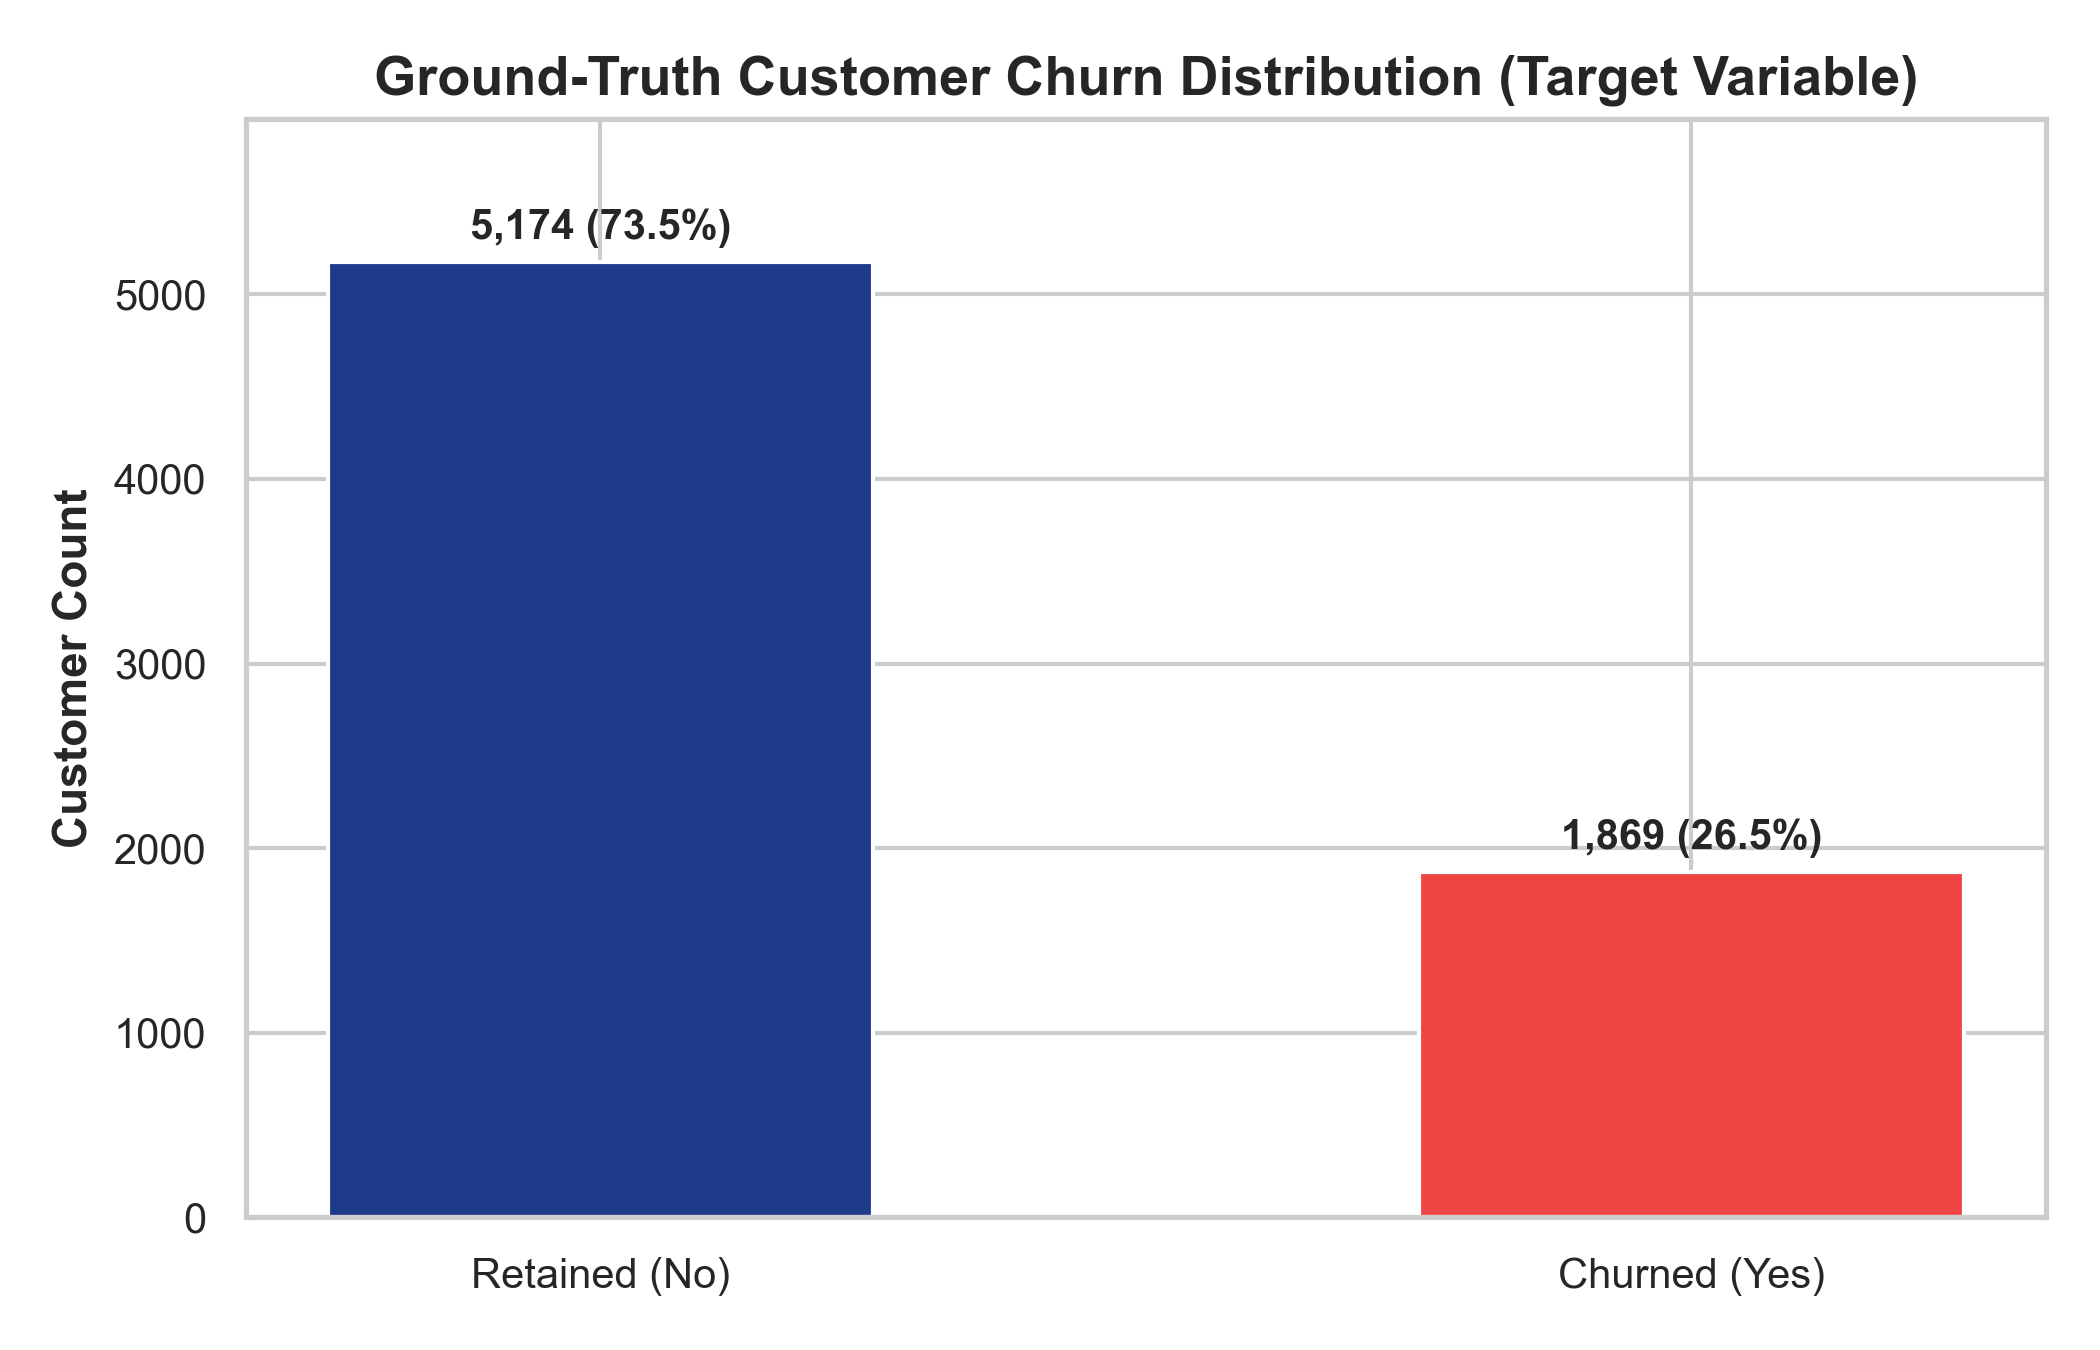

In [3]:
display(Image(filename=str(figures_dir / "01_target_distribution.png")))

### Q2: How does customer tenure relate to churn?
- **Finding**: Churn is heavily concentrated in early subscriber lifecycles.
- **Median Tenure**: Churned accounts have a median tenure of 10.0 months, compared to 38.0 months for retained accounts ($p < 10^{-100}$).
- **Observed Churn Rate by Tenure Cohort**: Customers with tenure $\le 12$ months exhibit an observed churn rate of **47.68%**, which drops to **6.61%** for customers with tenure $> 60$ months.

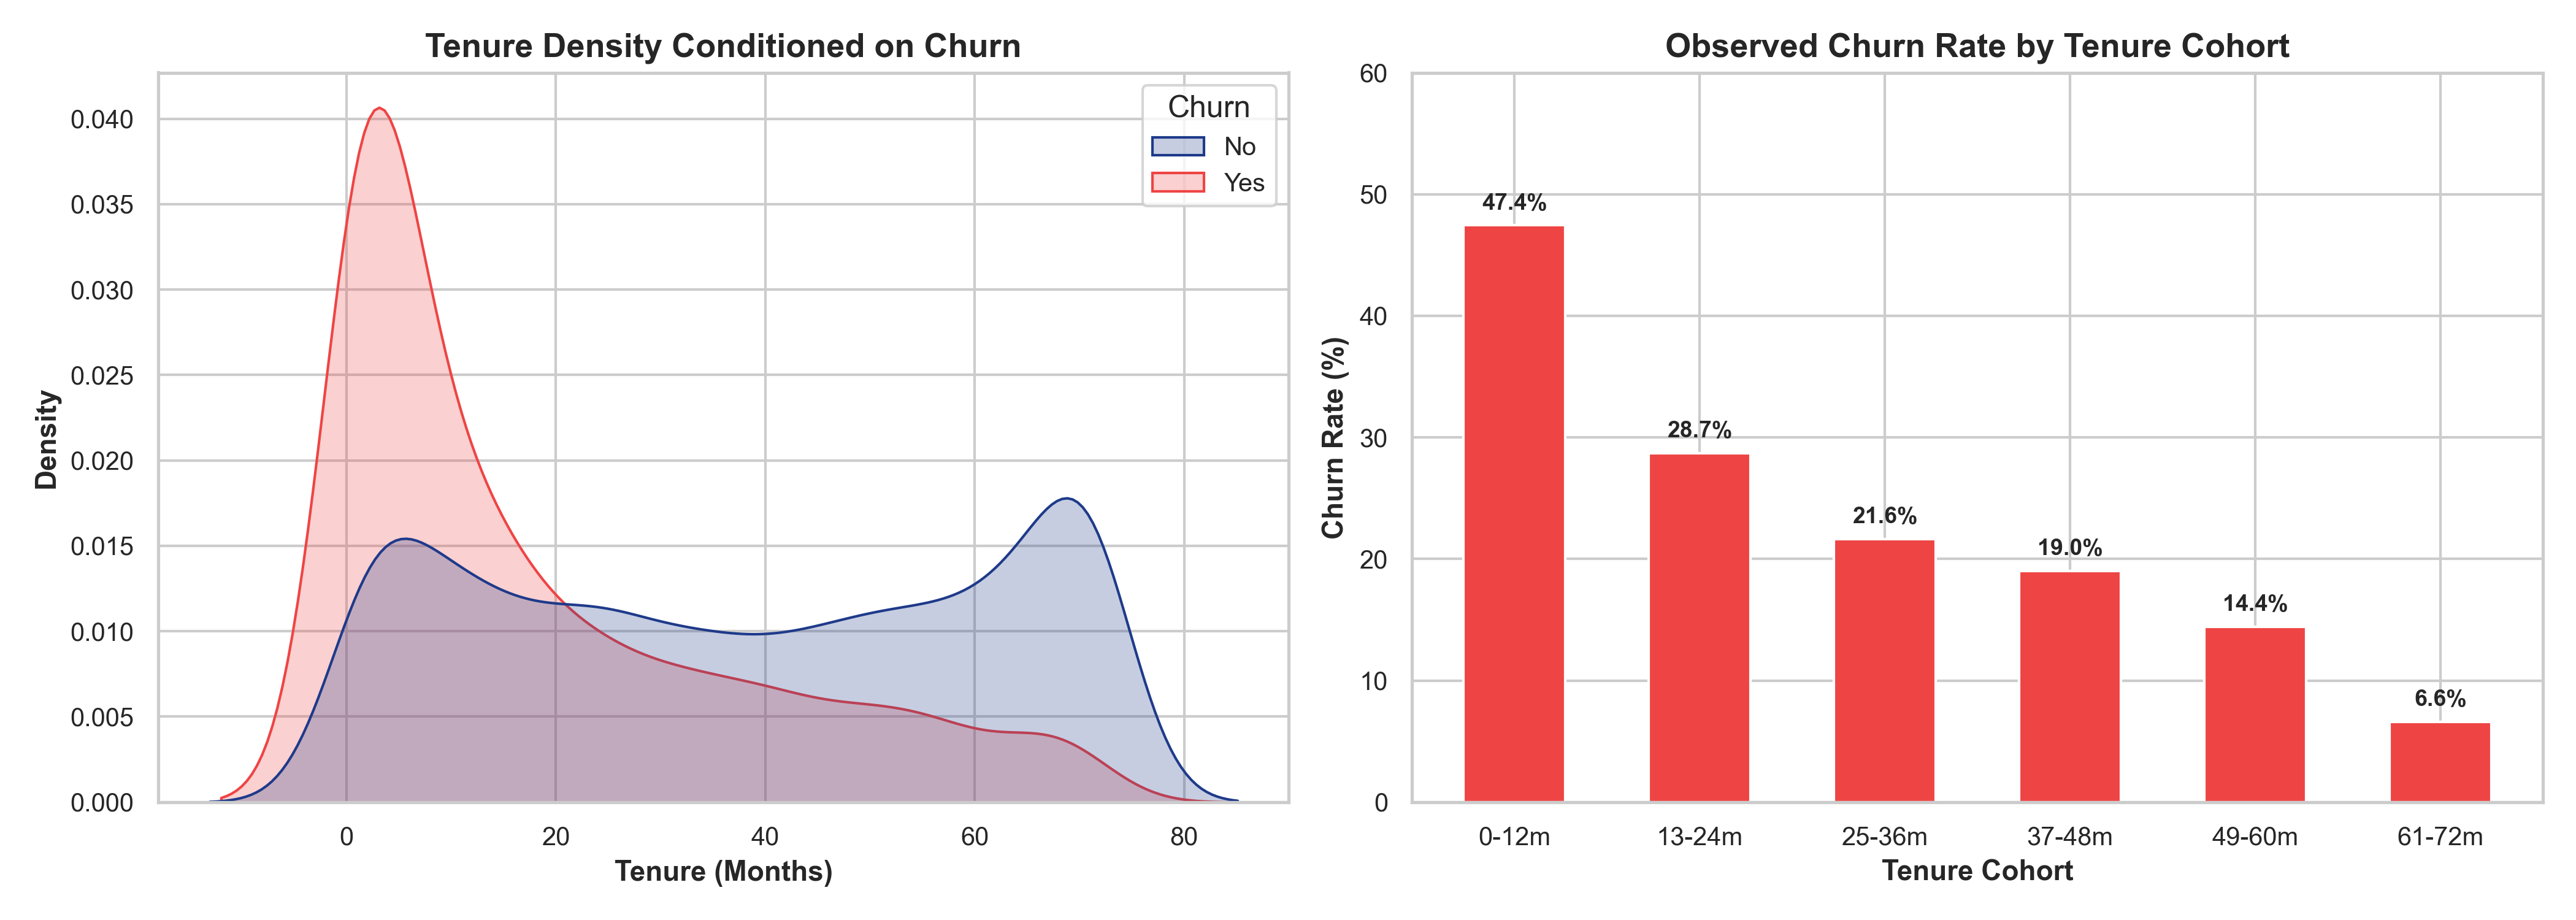

In [4]:
display(Image(filename=str(figures_dir / "03_tenure_vs_churn.png")))

### Q3: How do contract types differ in their observed churn rates?
- **Finding**: Contract commitment duration is the single strongest categorical factor.
- **Month-to-month**: 42.71% churn rate (3,875 accounts, 1,655 churns) — relative risk of 1.61x.
- **One year**: 11.27% churn rate (1,473 accounts, 166 churns).
- **Two year**: 2.83% churn rate (1,695 accounts, 48 churns) — relative risk of 0.11x.

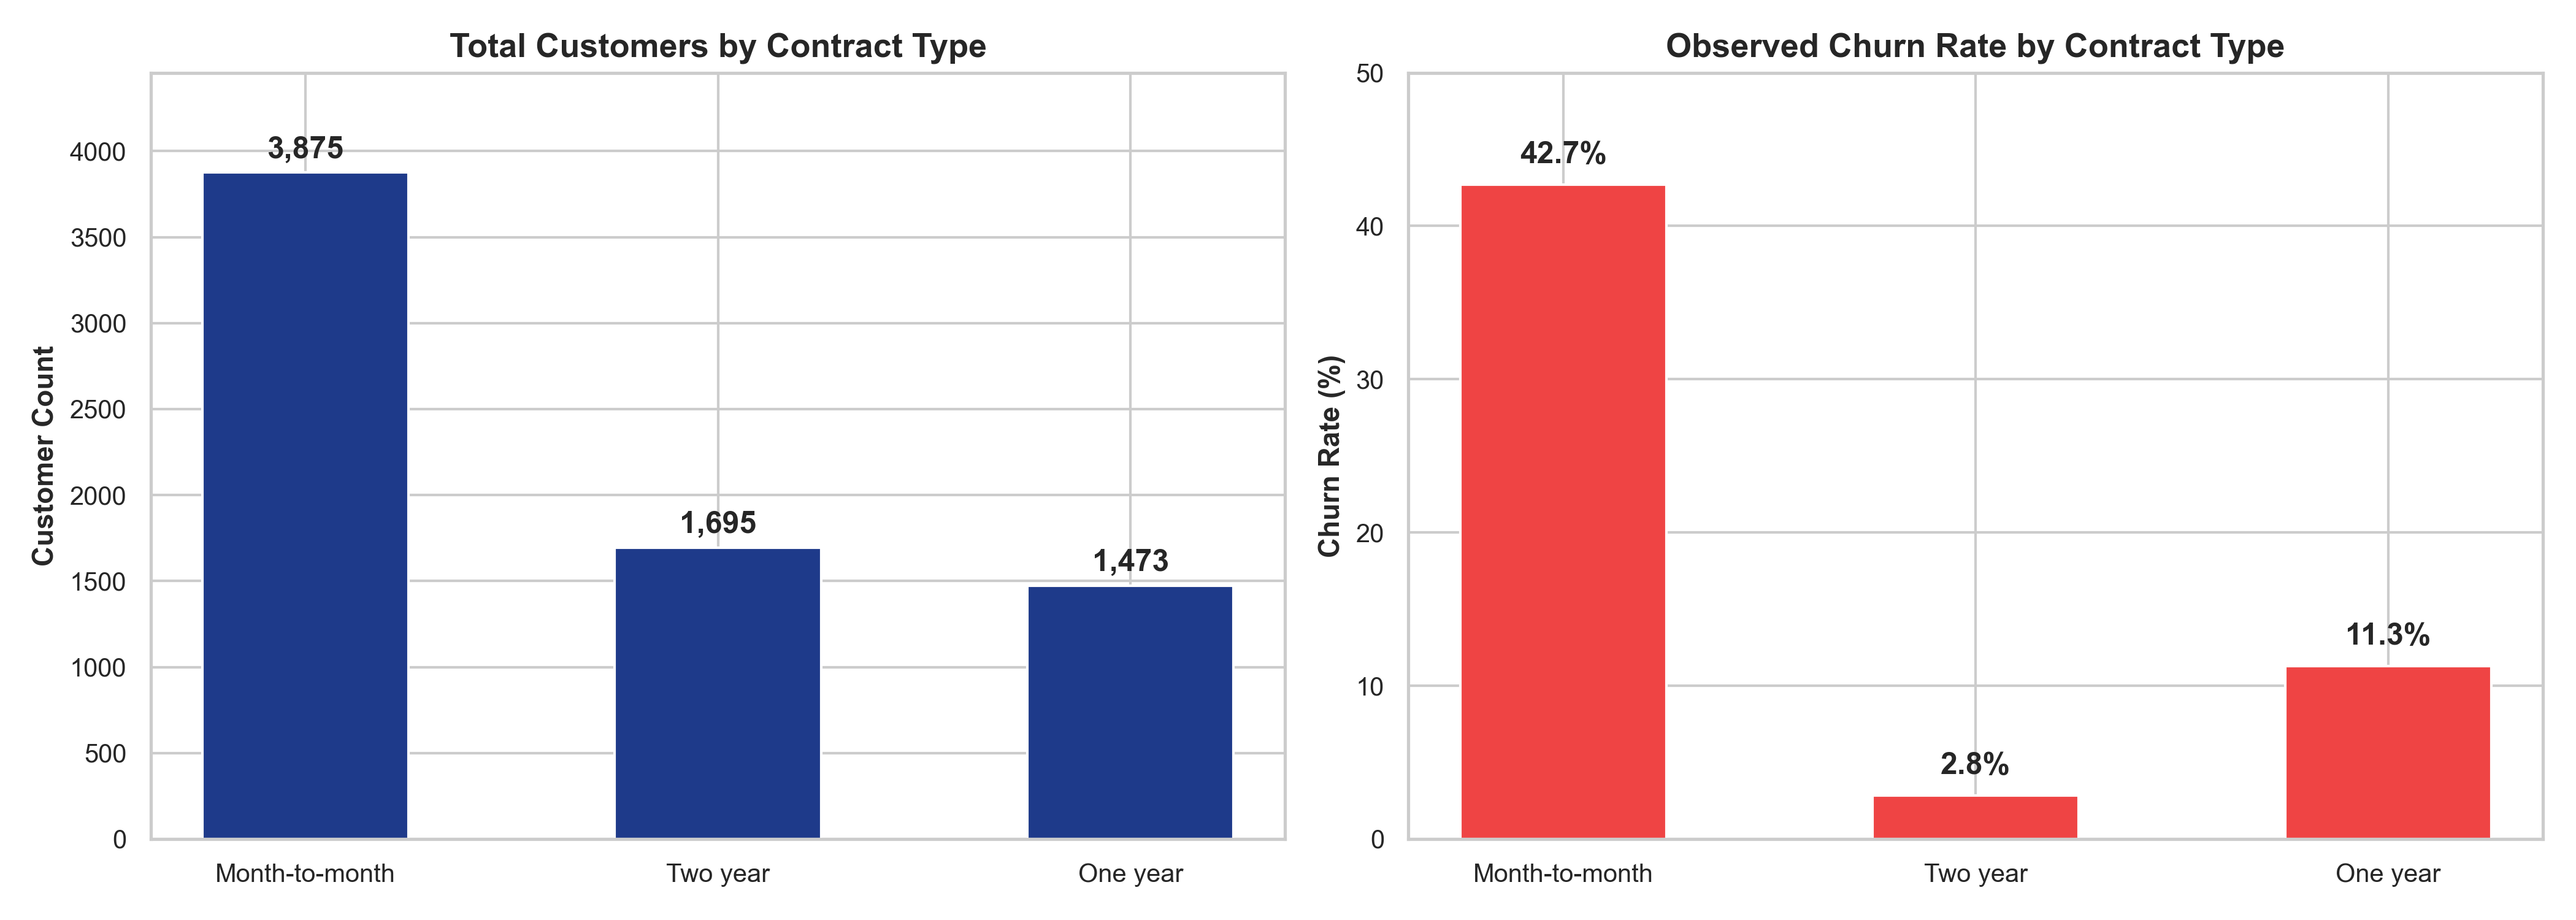

In [5]:
display(Image(filename=str(figures_dir / "06_churn_by_contract.png")))

### Q4: What relationship exists between MonthlyCharges and churn?
- **Finding**: Churned customers pay significantly higher monthly bills.
- **Means**: Churned customers average **$74.44/month**, compared to **$61.27/month** for retained customers (Welch's $t = 18.41, p < 10^{-70}$).
- **Distribution**: Higher attrition occurs in the $70–$100/month tier, driven heavily by Fiber Optic bundles without bundled support.

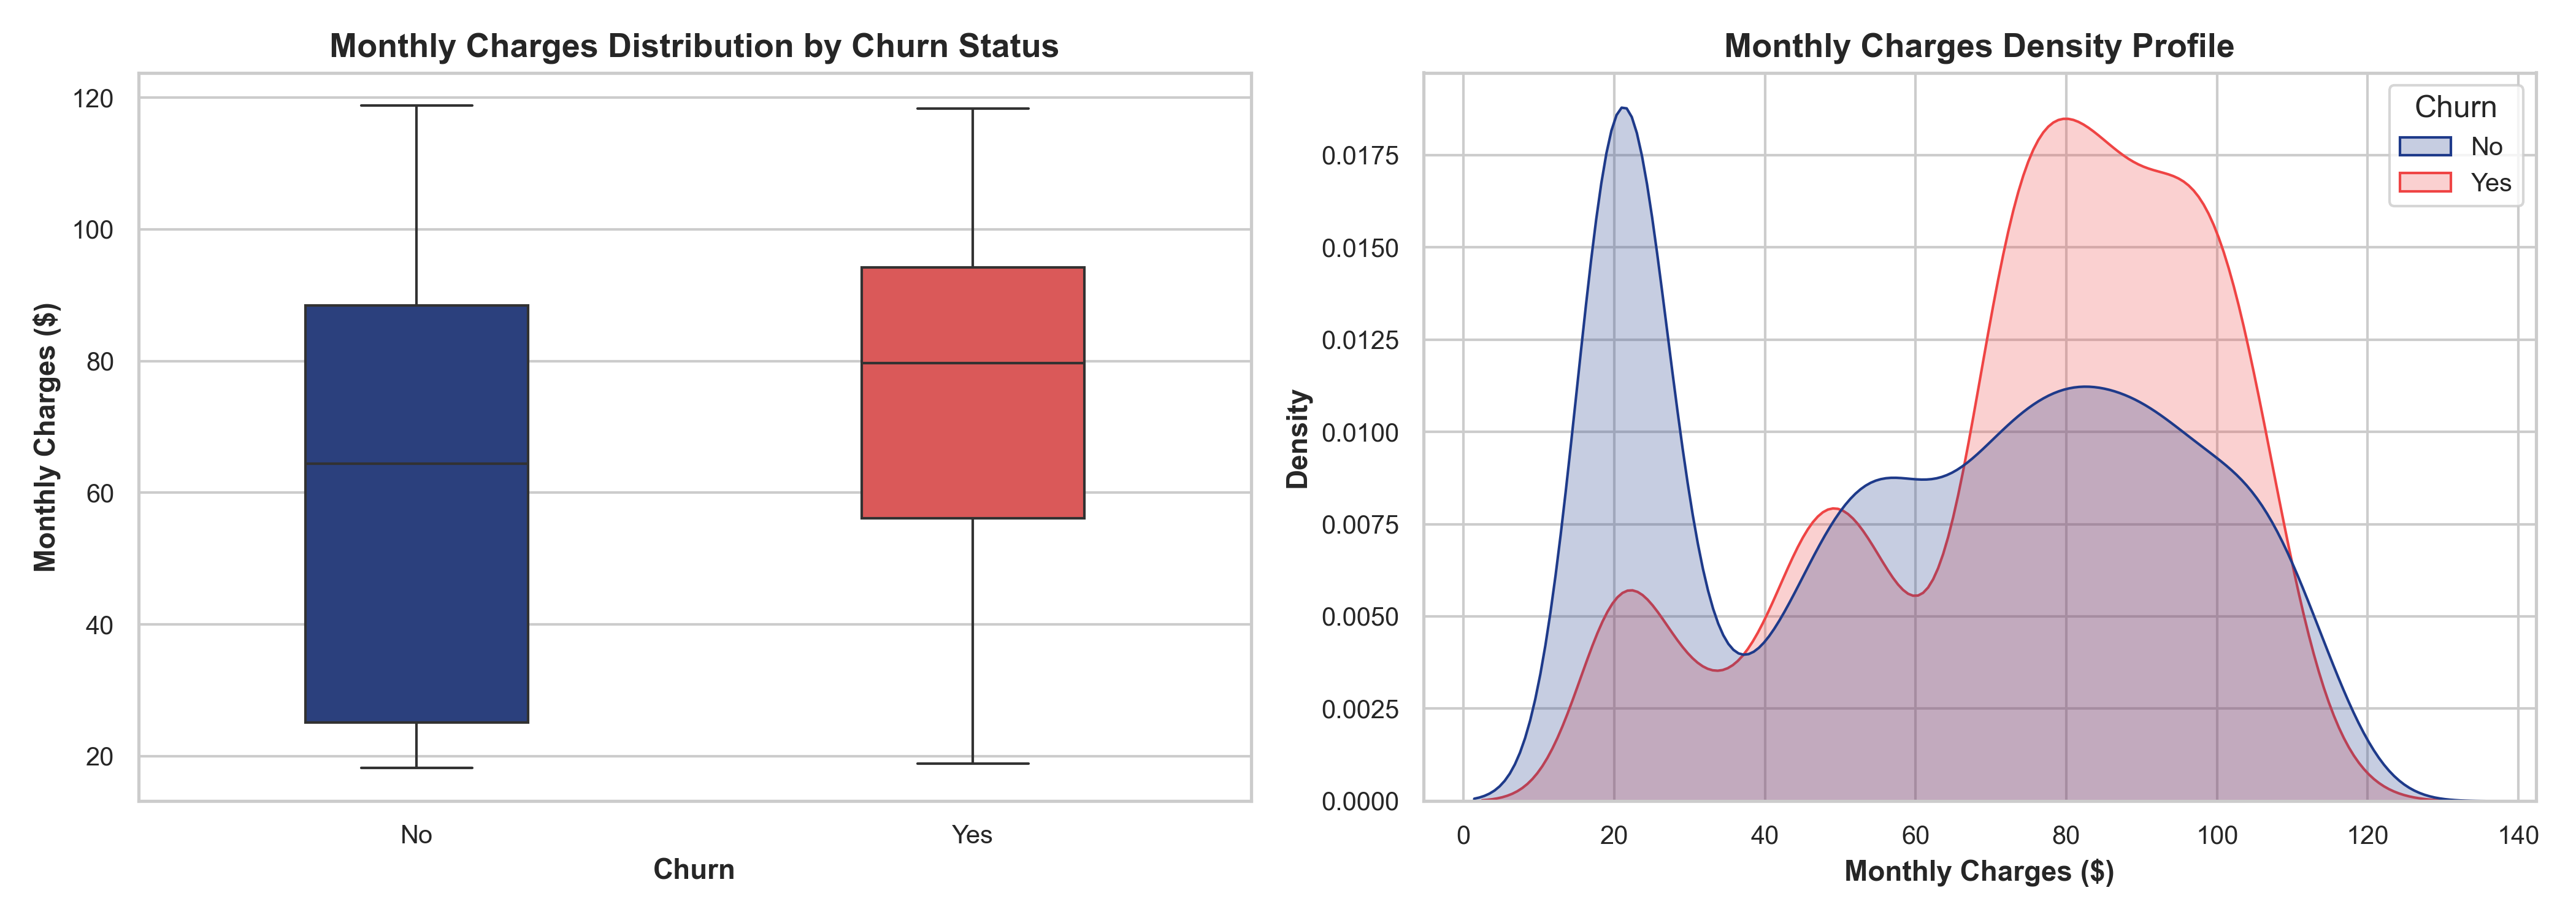

In [6]:
display(Image(filename=str(figures_dir / "04_monthly_charges_vs_churn.png")))

### Q5: How do InternetService, OnlineSecurity, and TechSupport relate to churn?
- **Internet Service**: Fiber Optic subscribers exhibit a **41.89%** churn rate, compared to **18.96%** for DSL and **7.40%** for No Internet.
- **Tech Support**: Accounts without Tech Support churn at **41.65%**, compared to **15.17%** for accounts with Tech Support.
- **Online Security**: Accounts without Online Security churn at **41.77%**, compared to **14.61%** with Online Security.

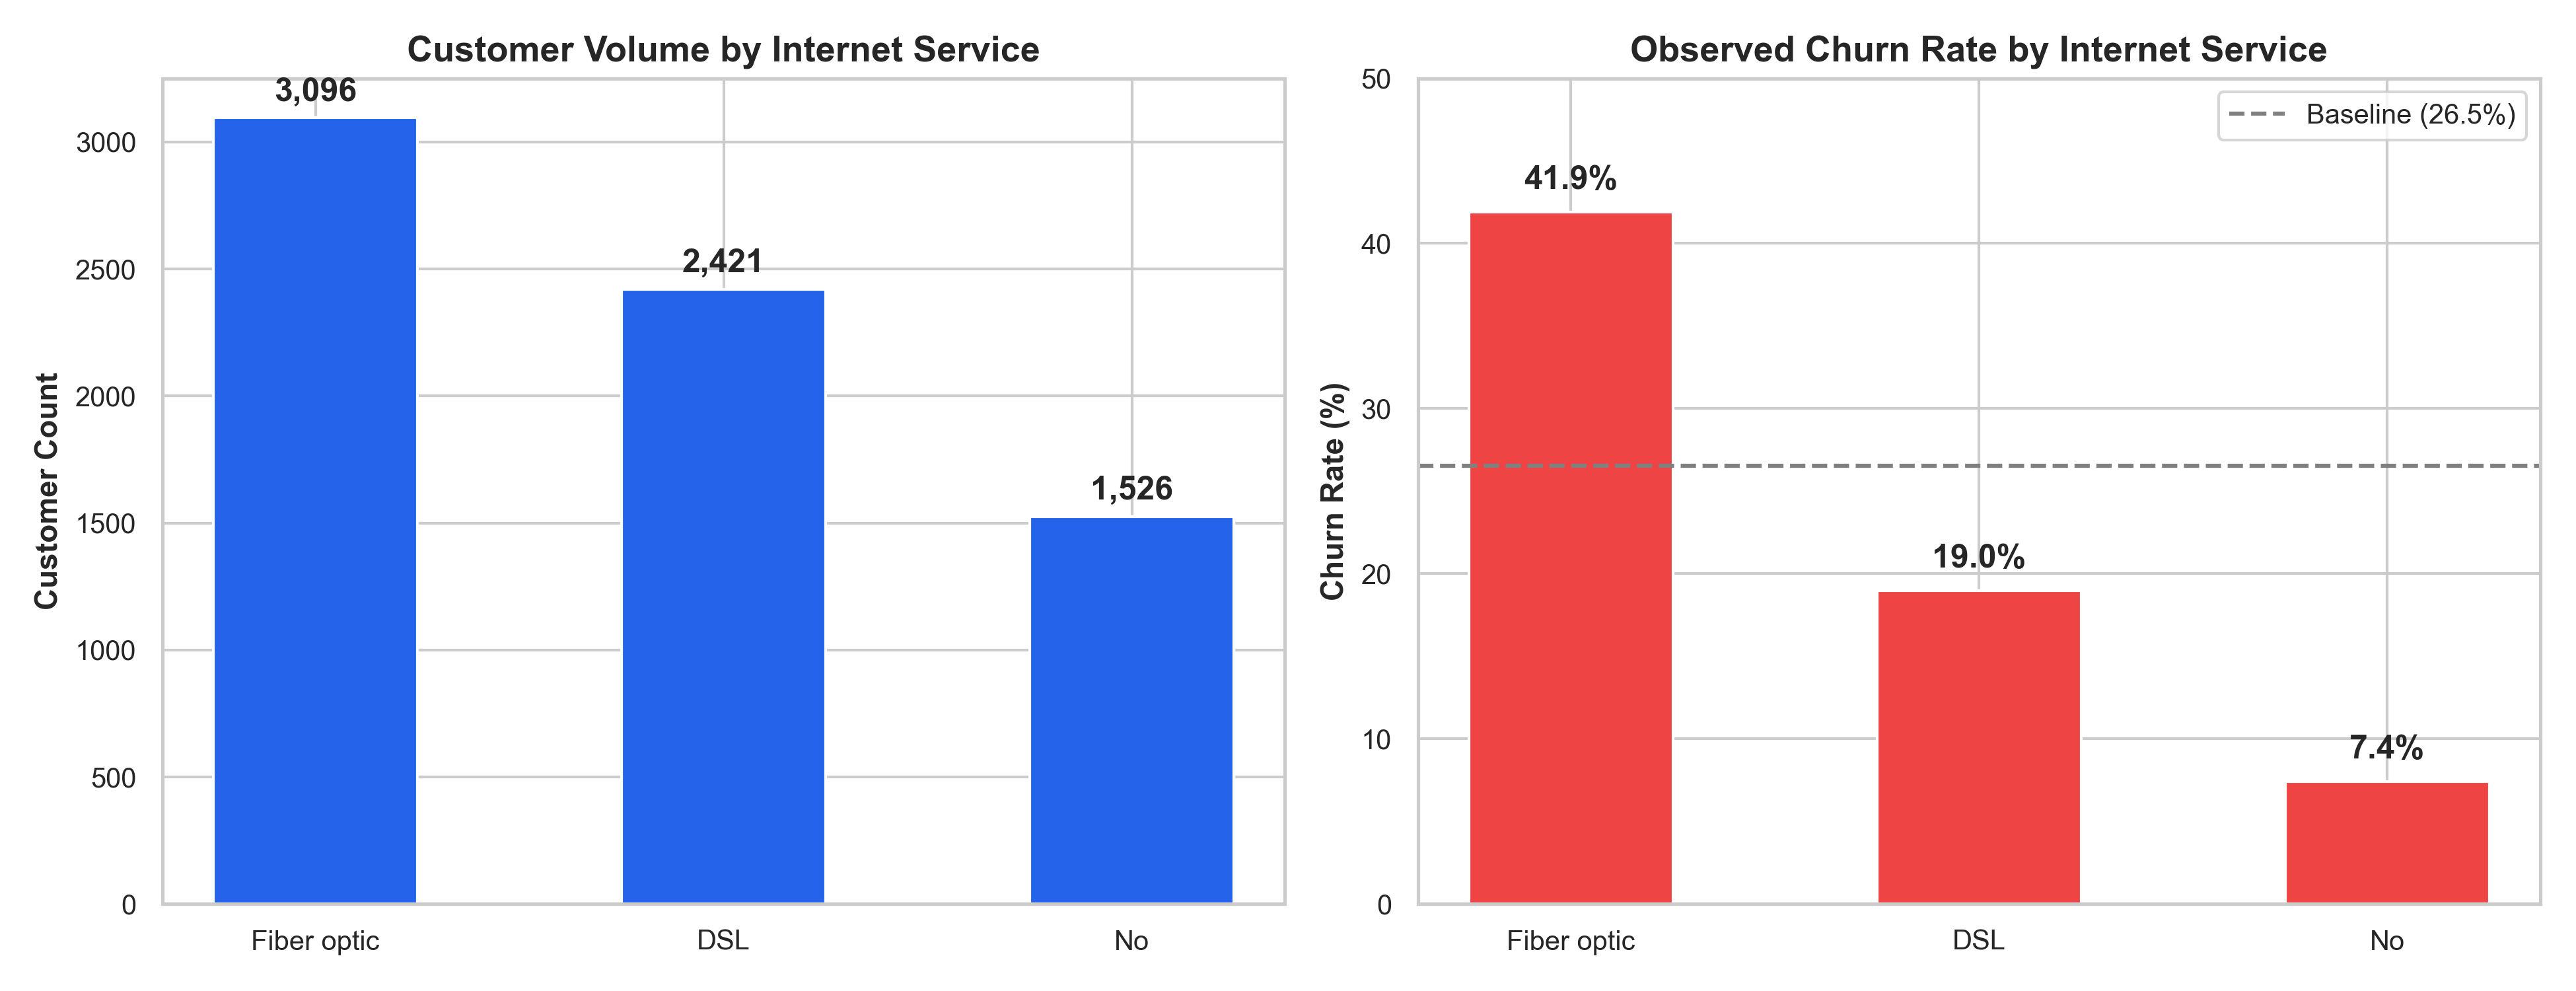

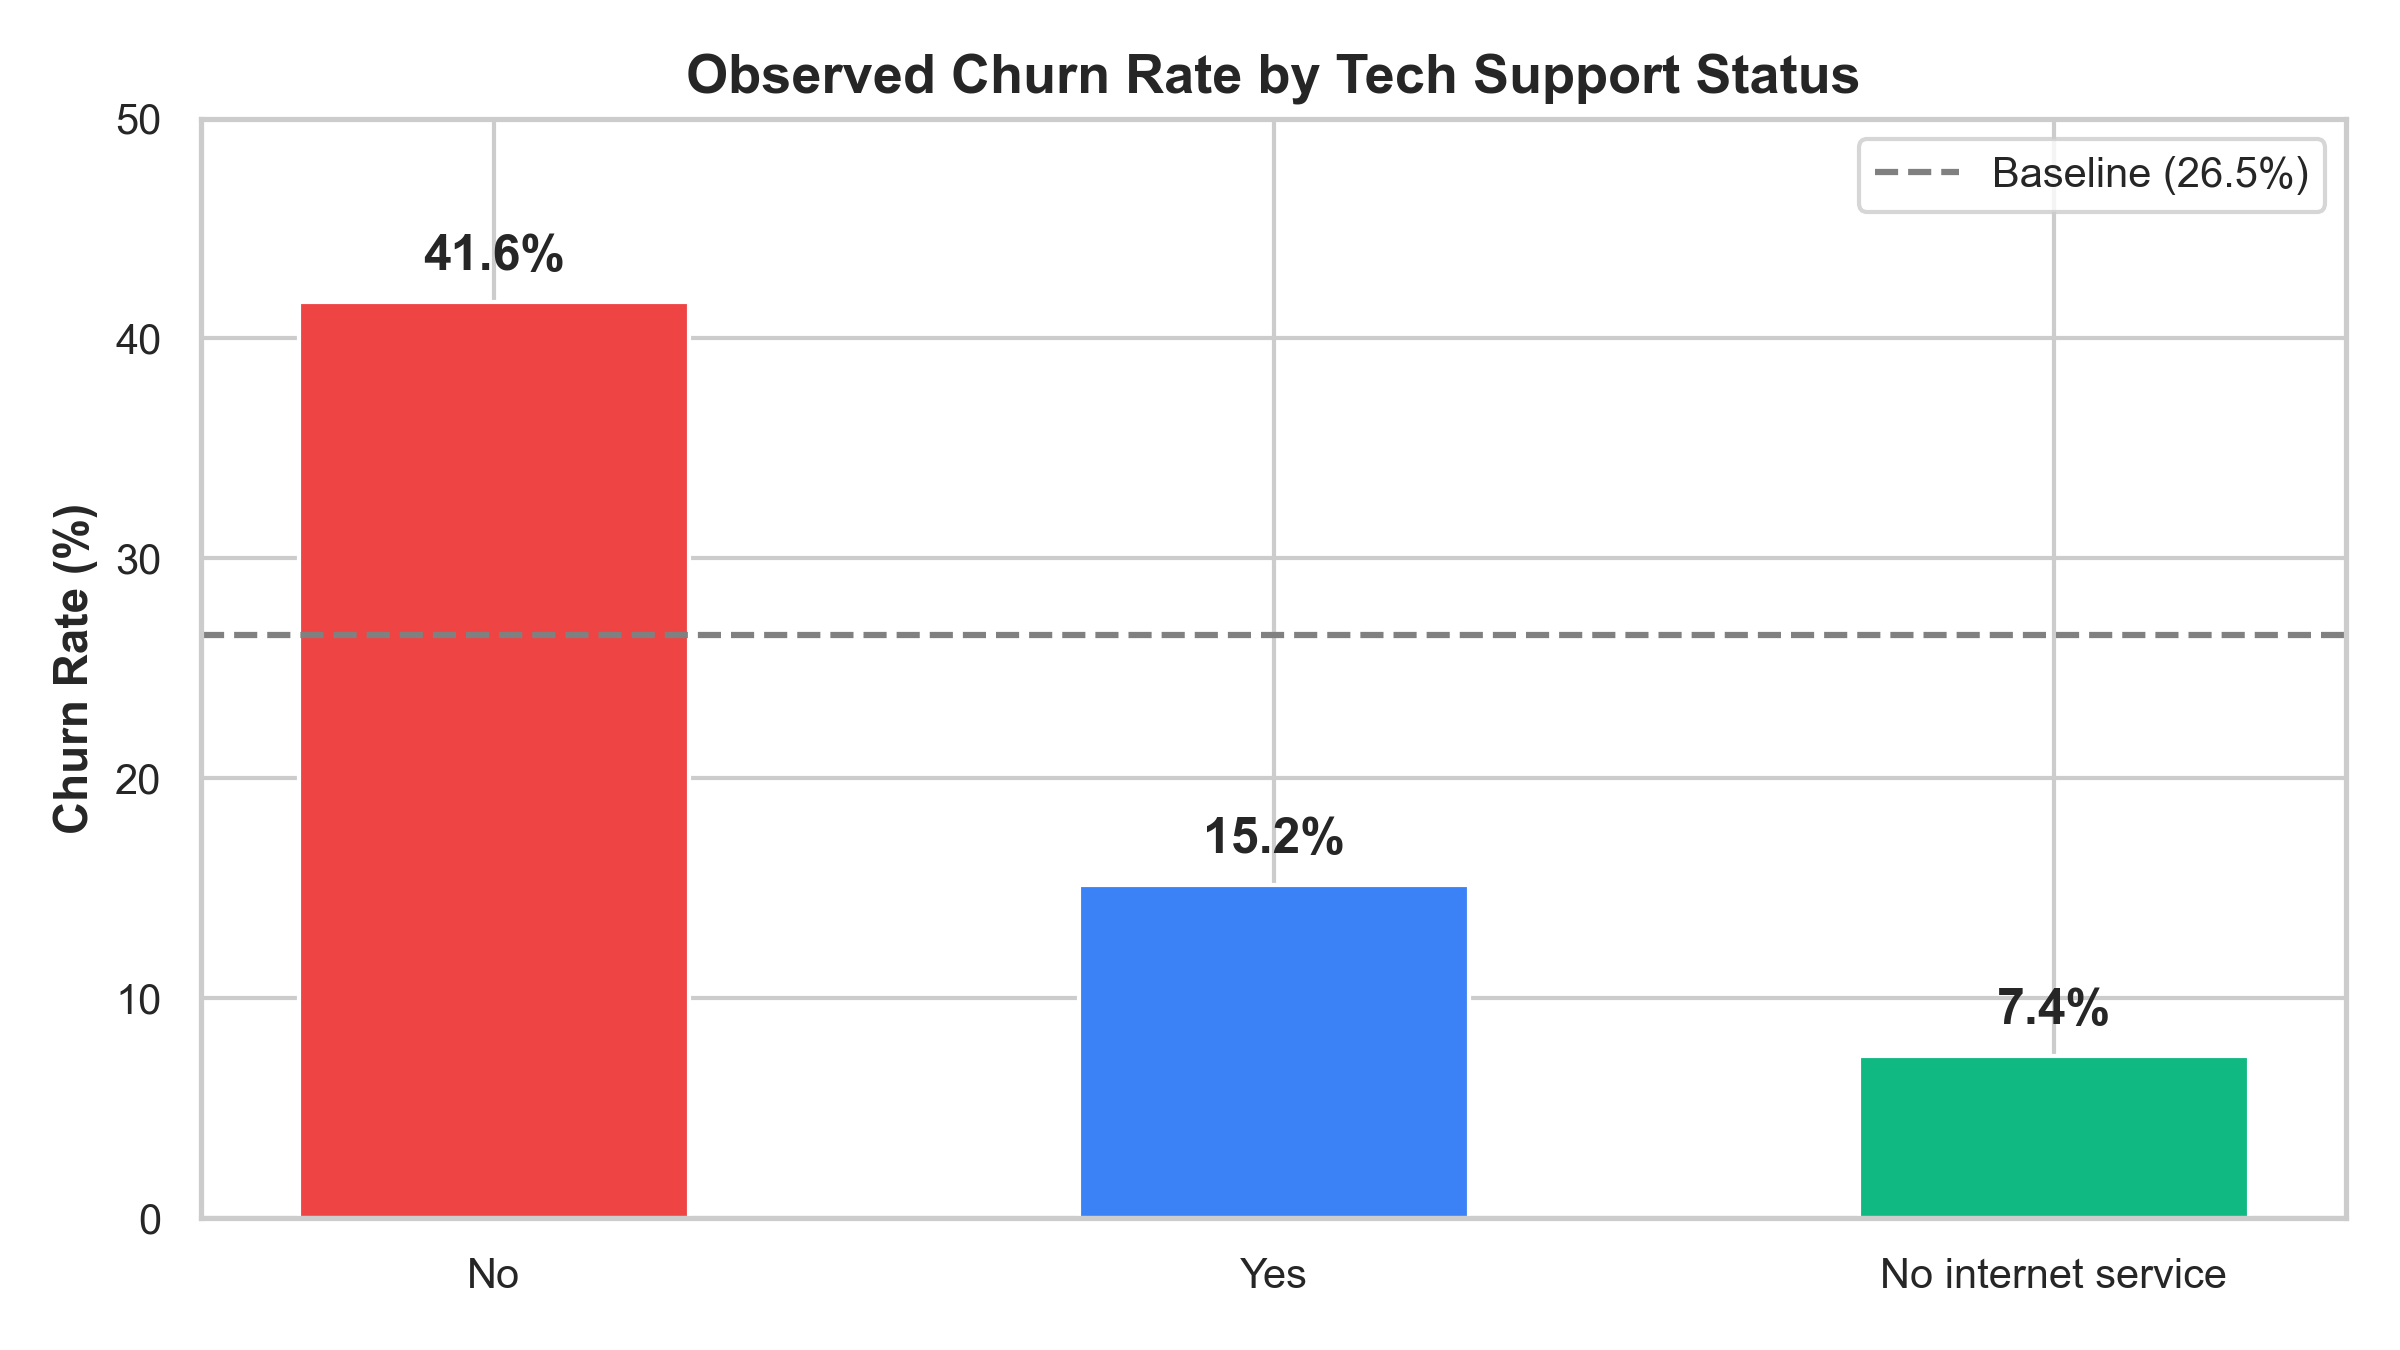

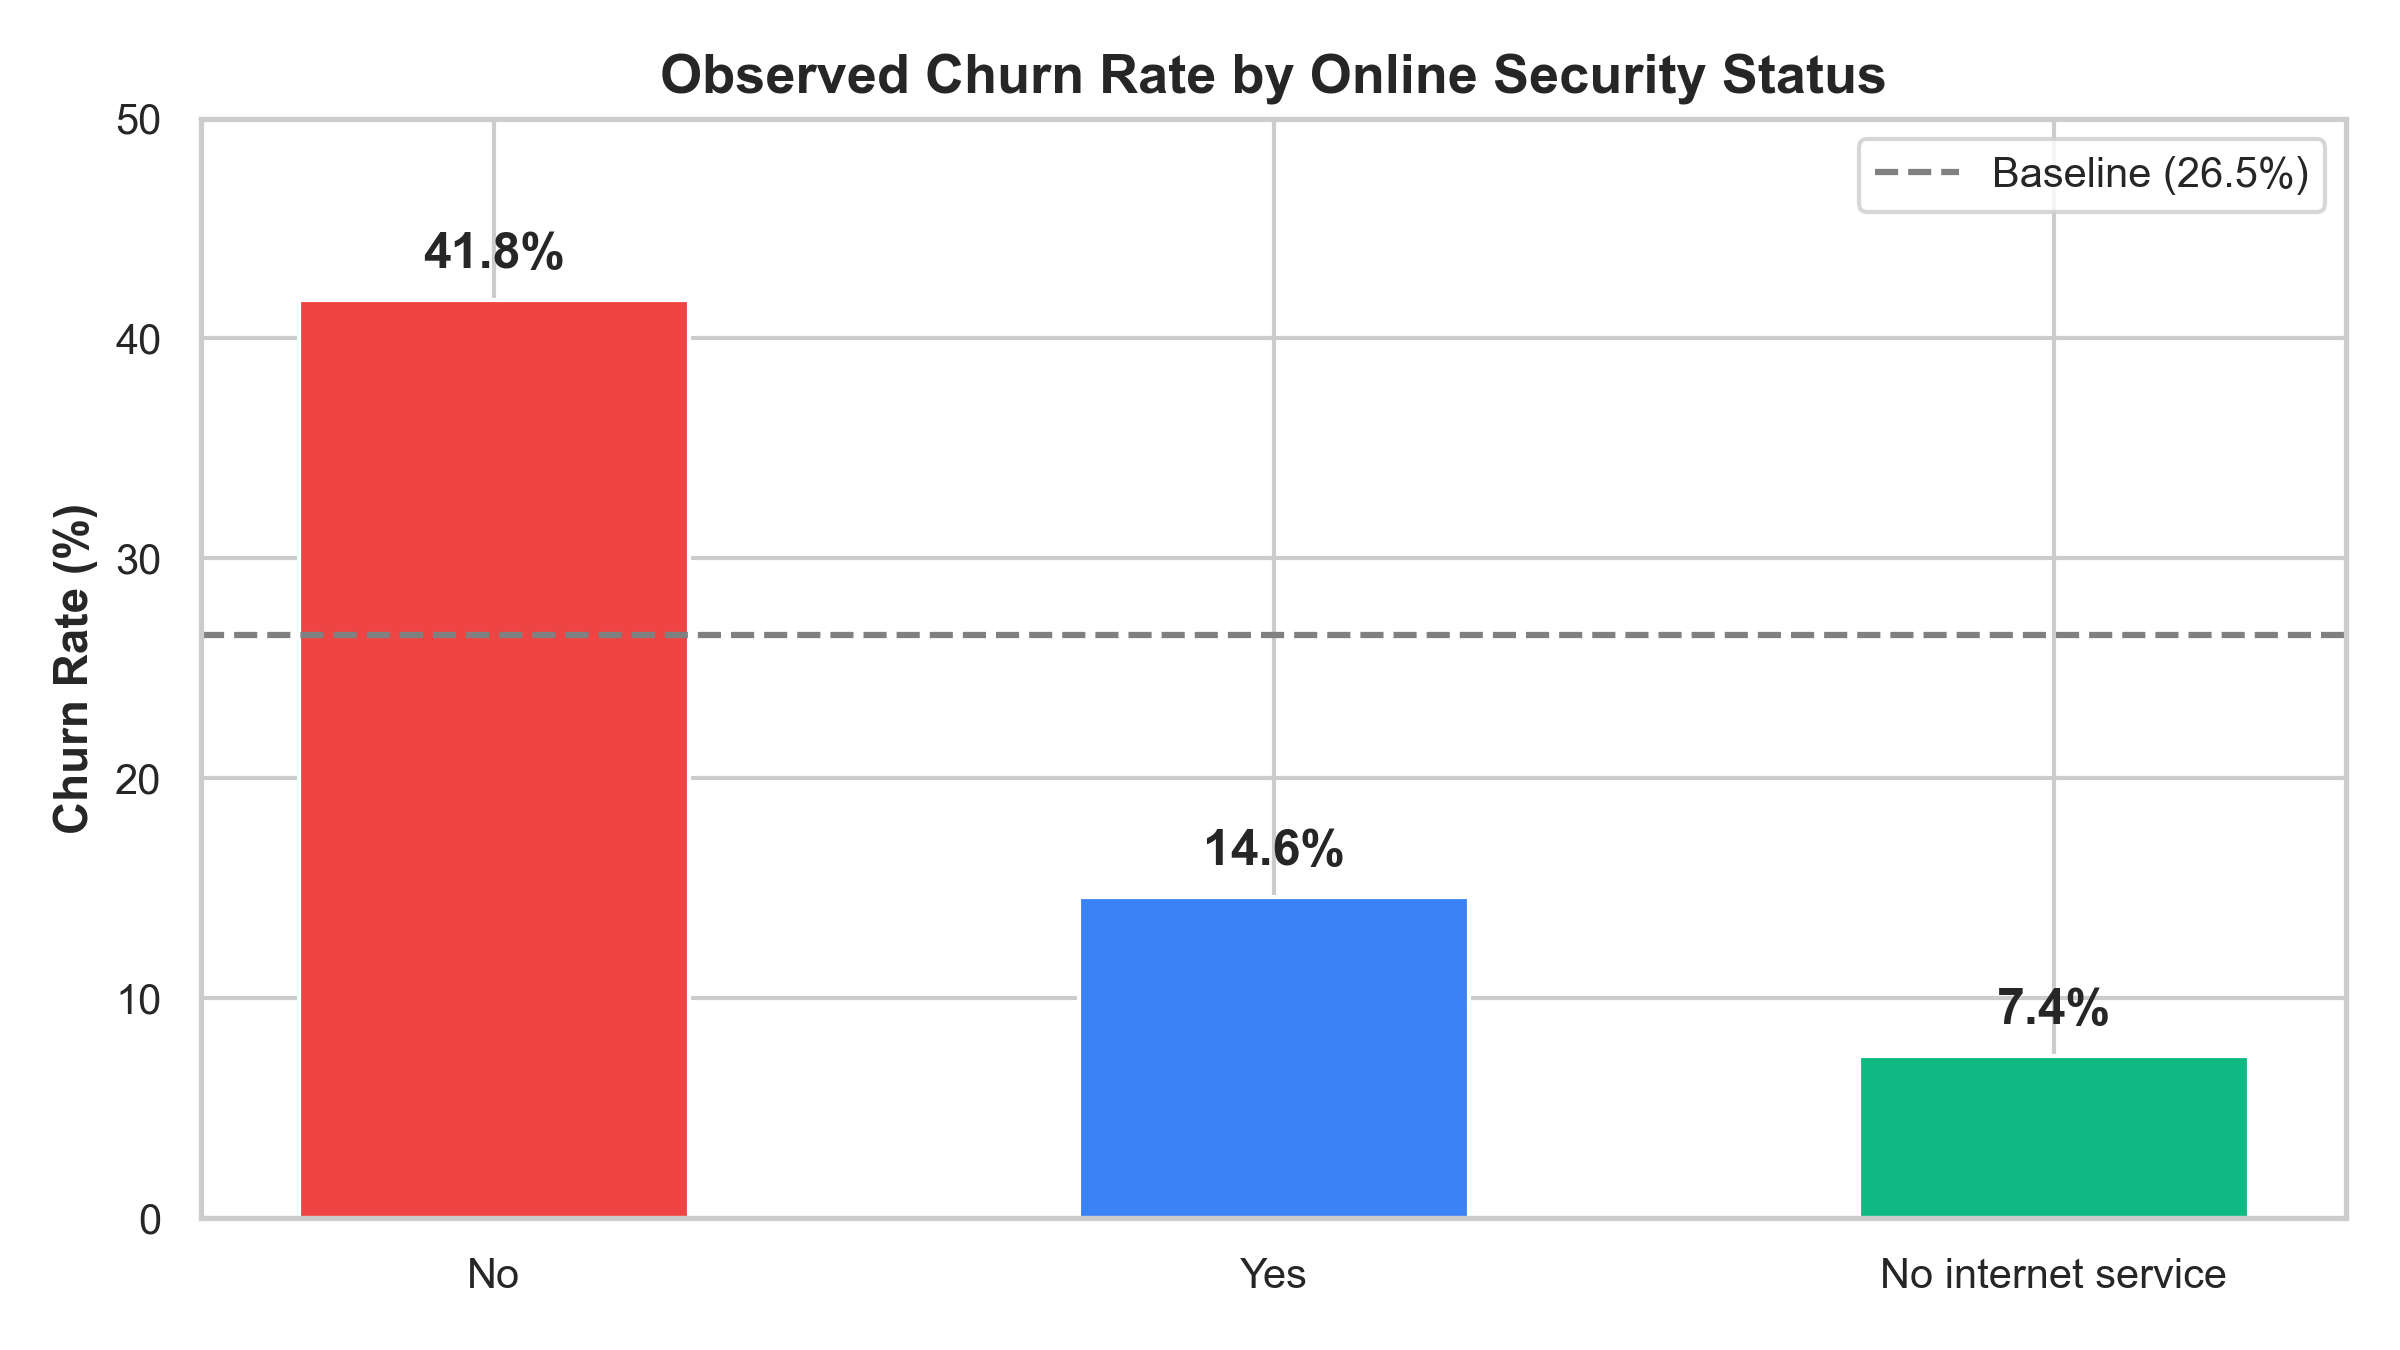

In [7]:
display(Image(filename=str(figures_dir / "08_churn_by_internet_service.png")))
display(Image(filename=str(figures_dir / "09_churn_by_tech_support.png")))
display(Image(filename=str(figures_dir / "10_churn_by_online_security.png")))

### Q6: Do payment methods show meaningful differences in churn rates?
- **Electronic Check**: Has the highest churn rate at **45.29%** (1,071 churns across 2,365 accounts; 1.71x baseline).
- **Automatic Payments**: Bank transfer (automatic) has a **16.71%** churn rate and Credit card (automatic) has a **15.24%** churn rate.
- **Mailed Check**: Shows an intermediate churn rate of **19.11%**.

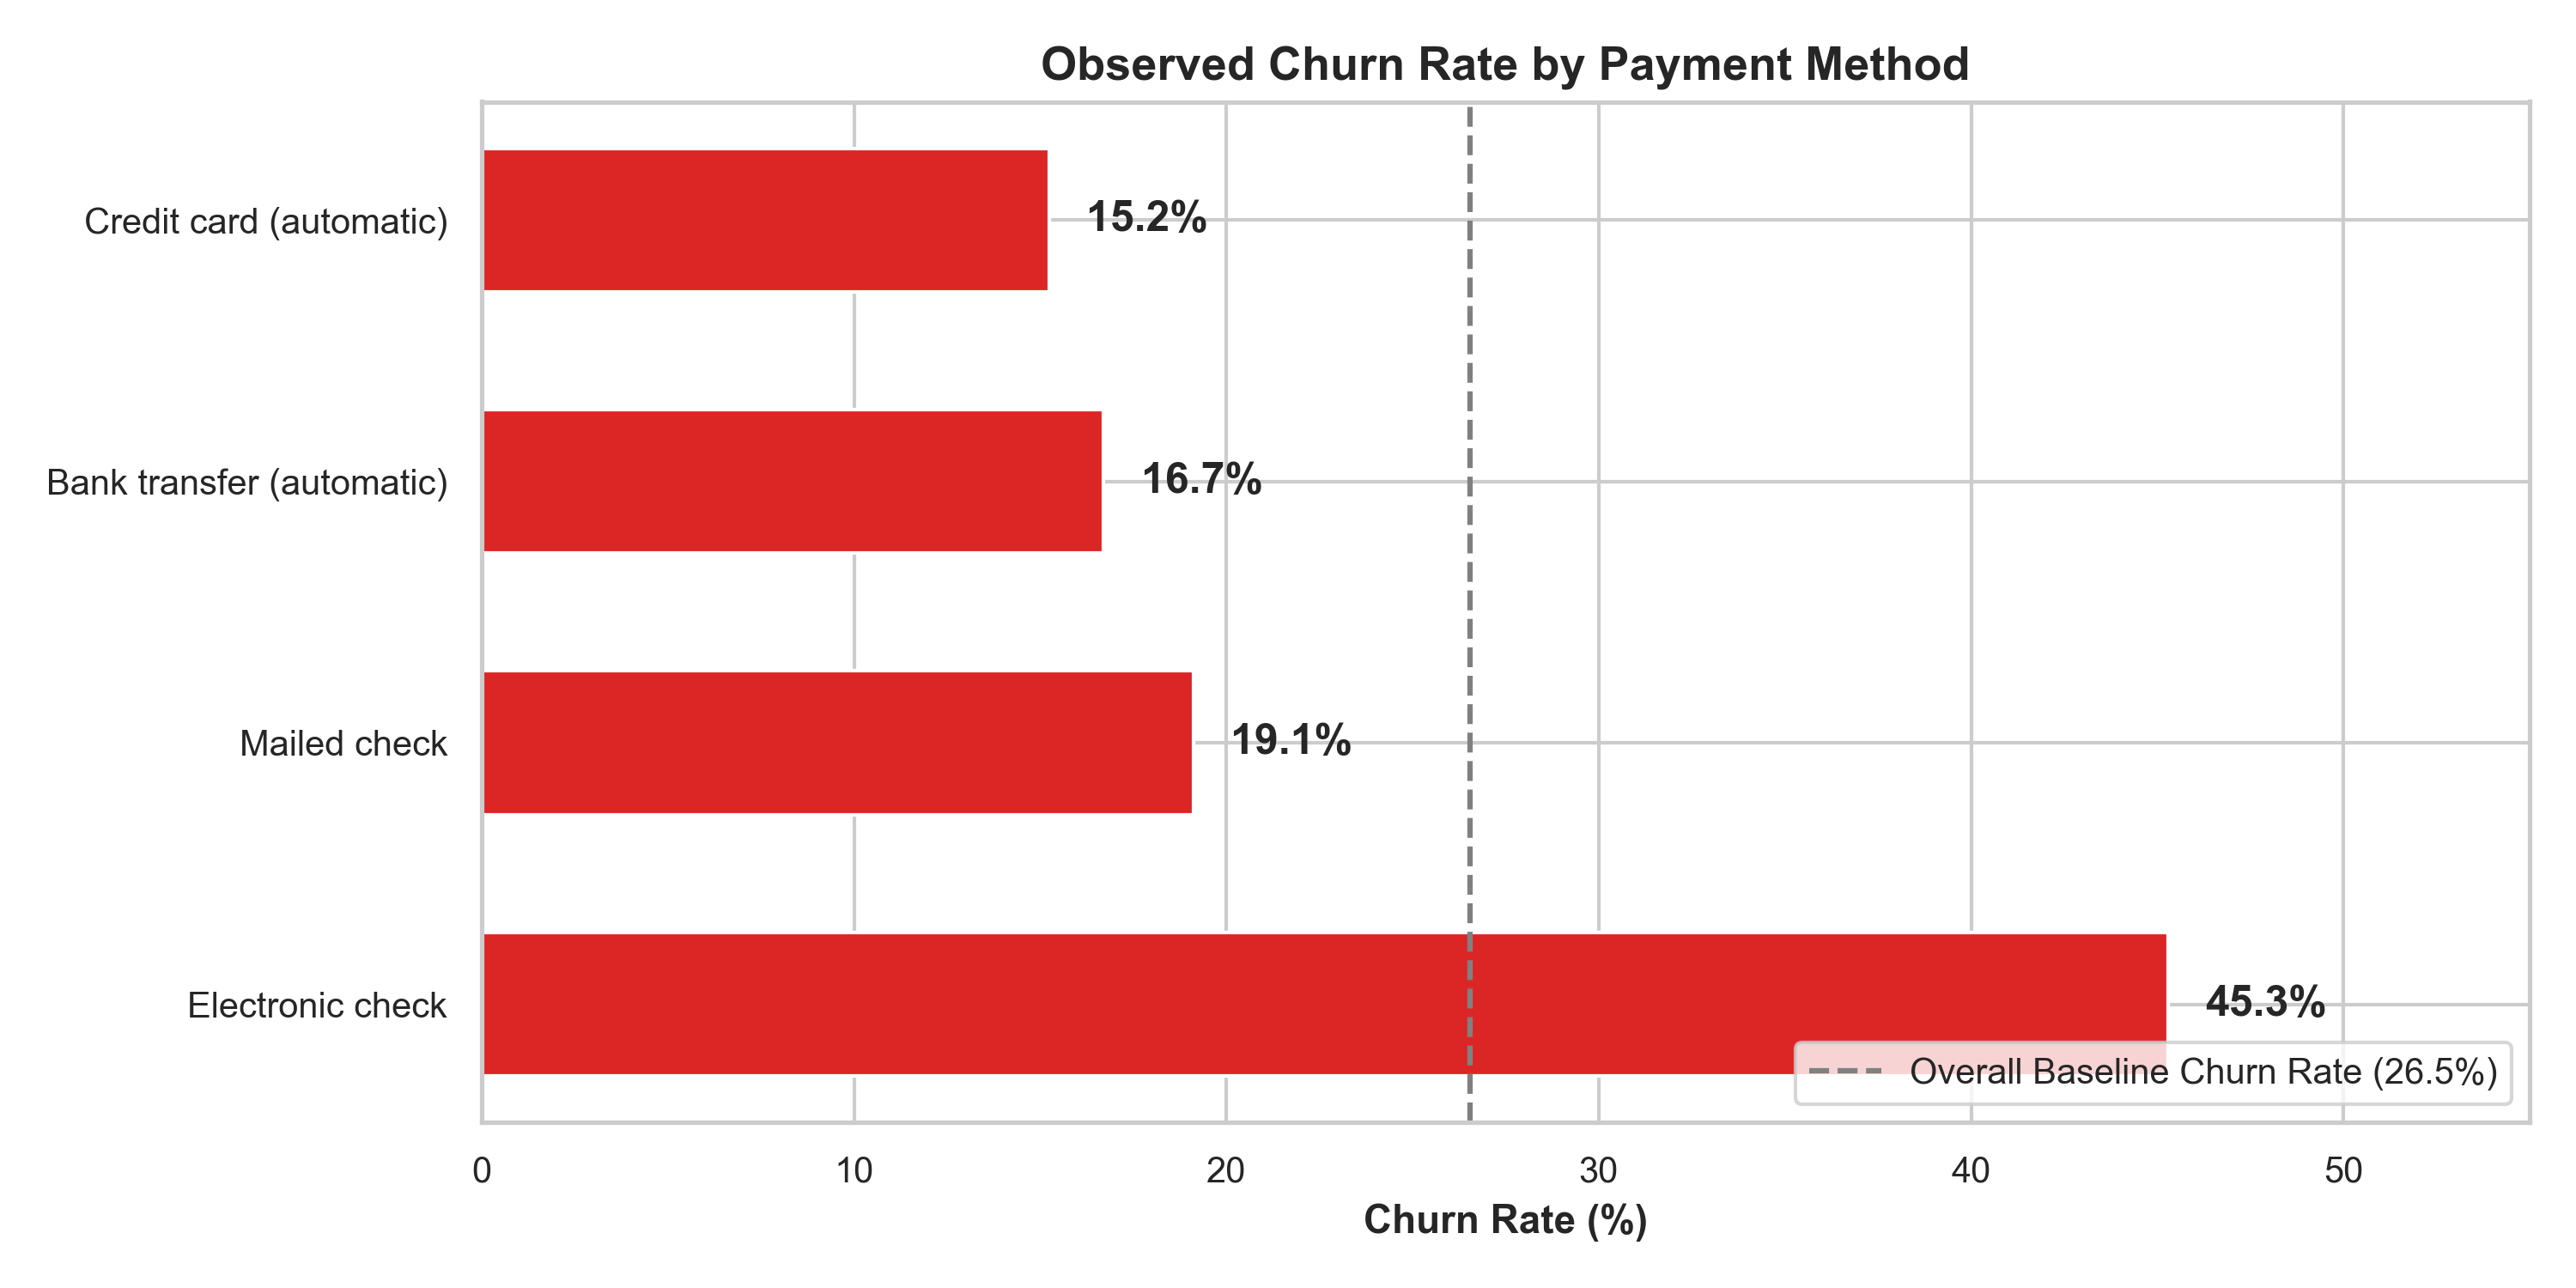

In [8]:
display(Image(filename=str(figures_dir / "07_churn_by_payment_method.png")))

### Q7: Are there meaningful differences across senior citizens, partners, and dependents?
- **Senior Citizens**: Churn at **41.68%** vs. **23.61%** for non-seniors (Cramér's V = 0.150, $p < 10^{-35}$).
- **Partners**: Customers with partners churn at **19.66%** vs. **32.96%** without partners.
- **Dependents**: Customers with dependents churn at **15.45%** vs. **31.28%** without dependents.

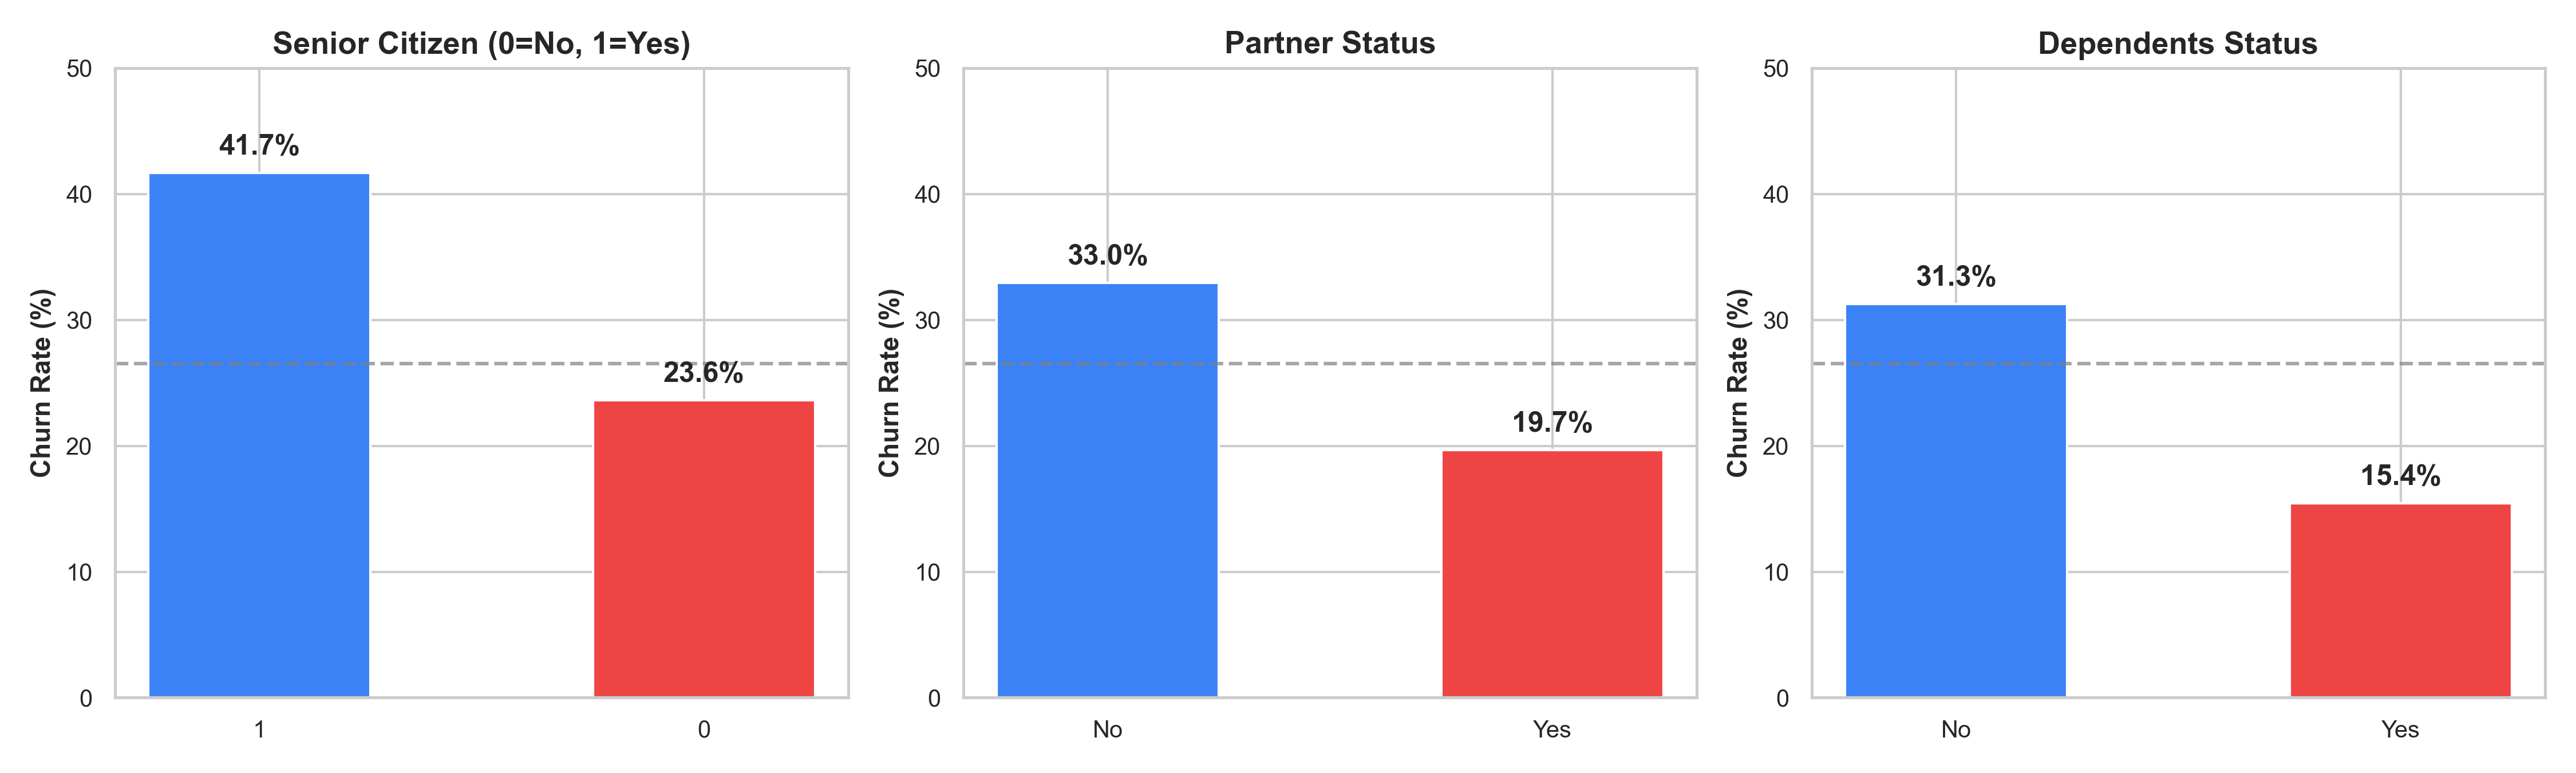

In [9]:
display(Image(filename=str(figures_dir / "11_churn_by_demographics.png")))

### Q8: What is the relationship between TotalCharges and tenure, and what should happen to the 11 whitespace-only values?
- **Correlation**: Spearman rank correlation between valid TotalCharges and tenure is **0.889**, confirming that TotalCharges is accumulated billing over tenure ($\approx \text{tenure} \times \text{MonthlyCharges}$).
- **Tenure == 1 Consistency**: For all 613 customers with `tenure == 1`, `TotalCharges` exactly matches `MonthlyCharges` ($\Delta = 0.00$).
- **Whitespace Rows**: All 11 whitespace records have `tenure == 0` and `Churn == "No"`. At month 0, accumulated billed revenue is operationally $0.00.
- **Recommendation**: Impute `0.0` during Phase 3 preprocessing.

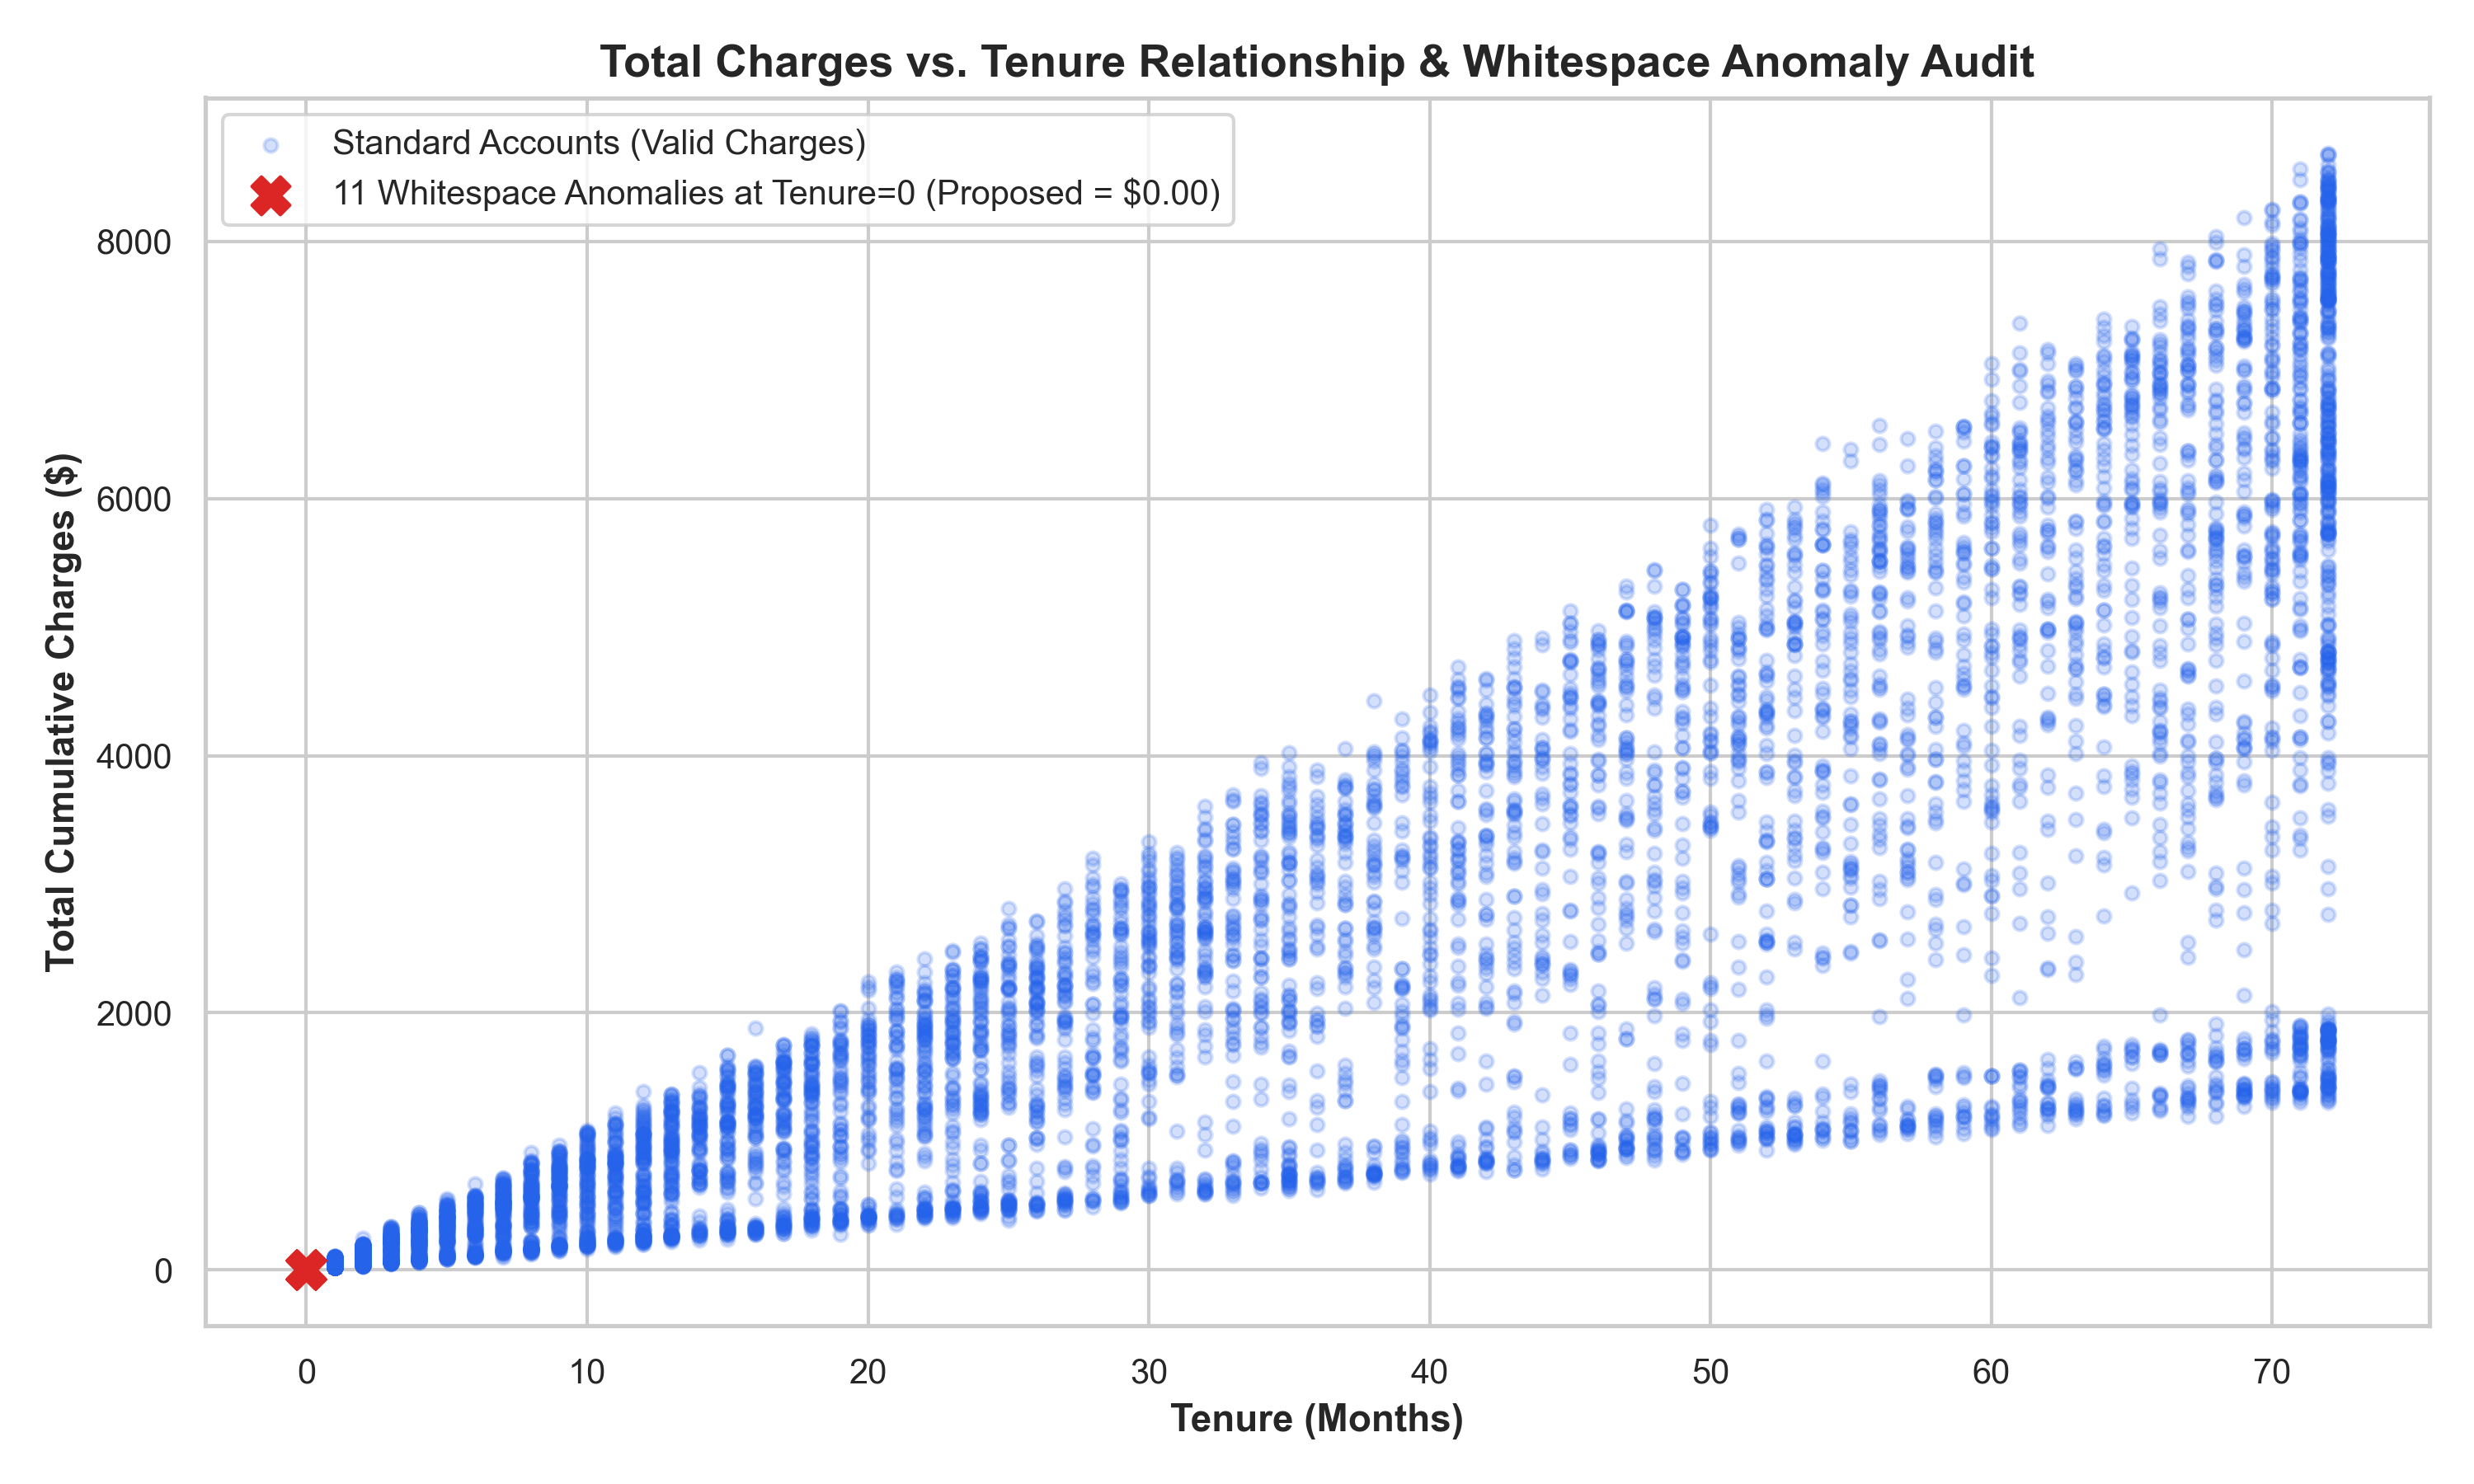

In [10]:
display(Image(filename=str(figures_dir / "14_total_charges_tenure_investigation.png")))

### Q9: Which features show the strongest descriptive associations with churn?
- **Top Categorical Associations** (Bias-Corrected Cramér's V):
  1. `Contract`: $V = 0.408$
  2. `OnlineSecurity`: $V = 0.347$
  3. `TechSupport`: $V = 0.344$
  4. `InternetService`: $V = 0.320$
  5. `PaymentMethod`: $V = 0.302$
- **Top Numerical Associations** (Rank-Biserial Correlation):
  1. `tenure`: $r = -0.370$ ($p < 10^{-100}$)
  2. `MonthlyCharges`: $r = +0.228$ ($p < 10^{-70}$)
  3. `TotalCharges`: $r = -0.231$ ($p < 10^{-50}$)

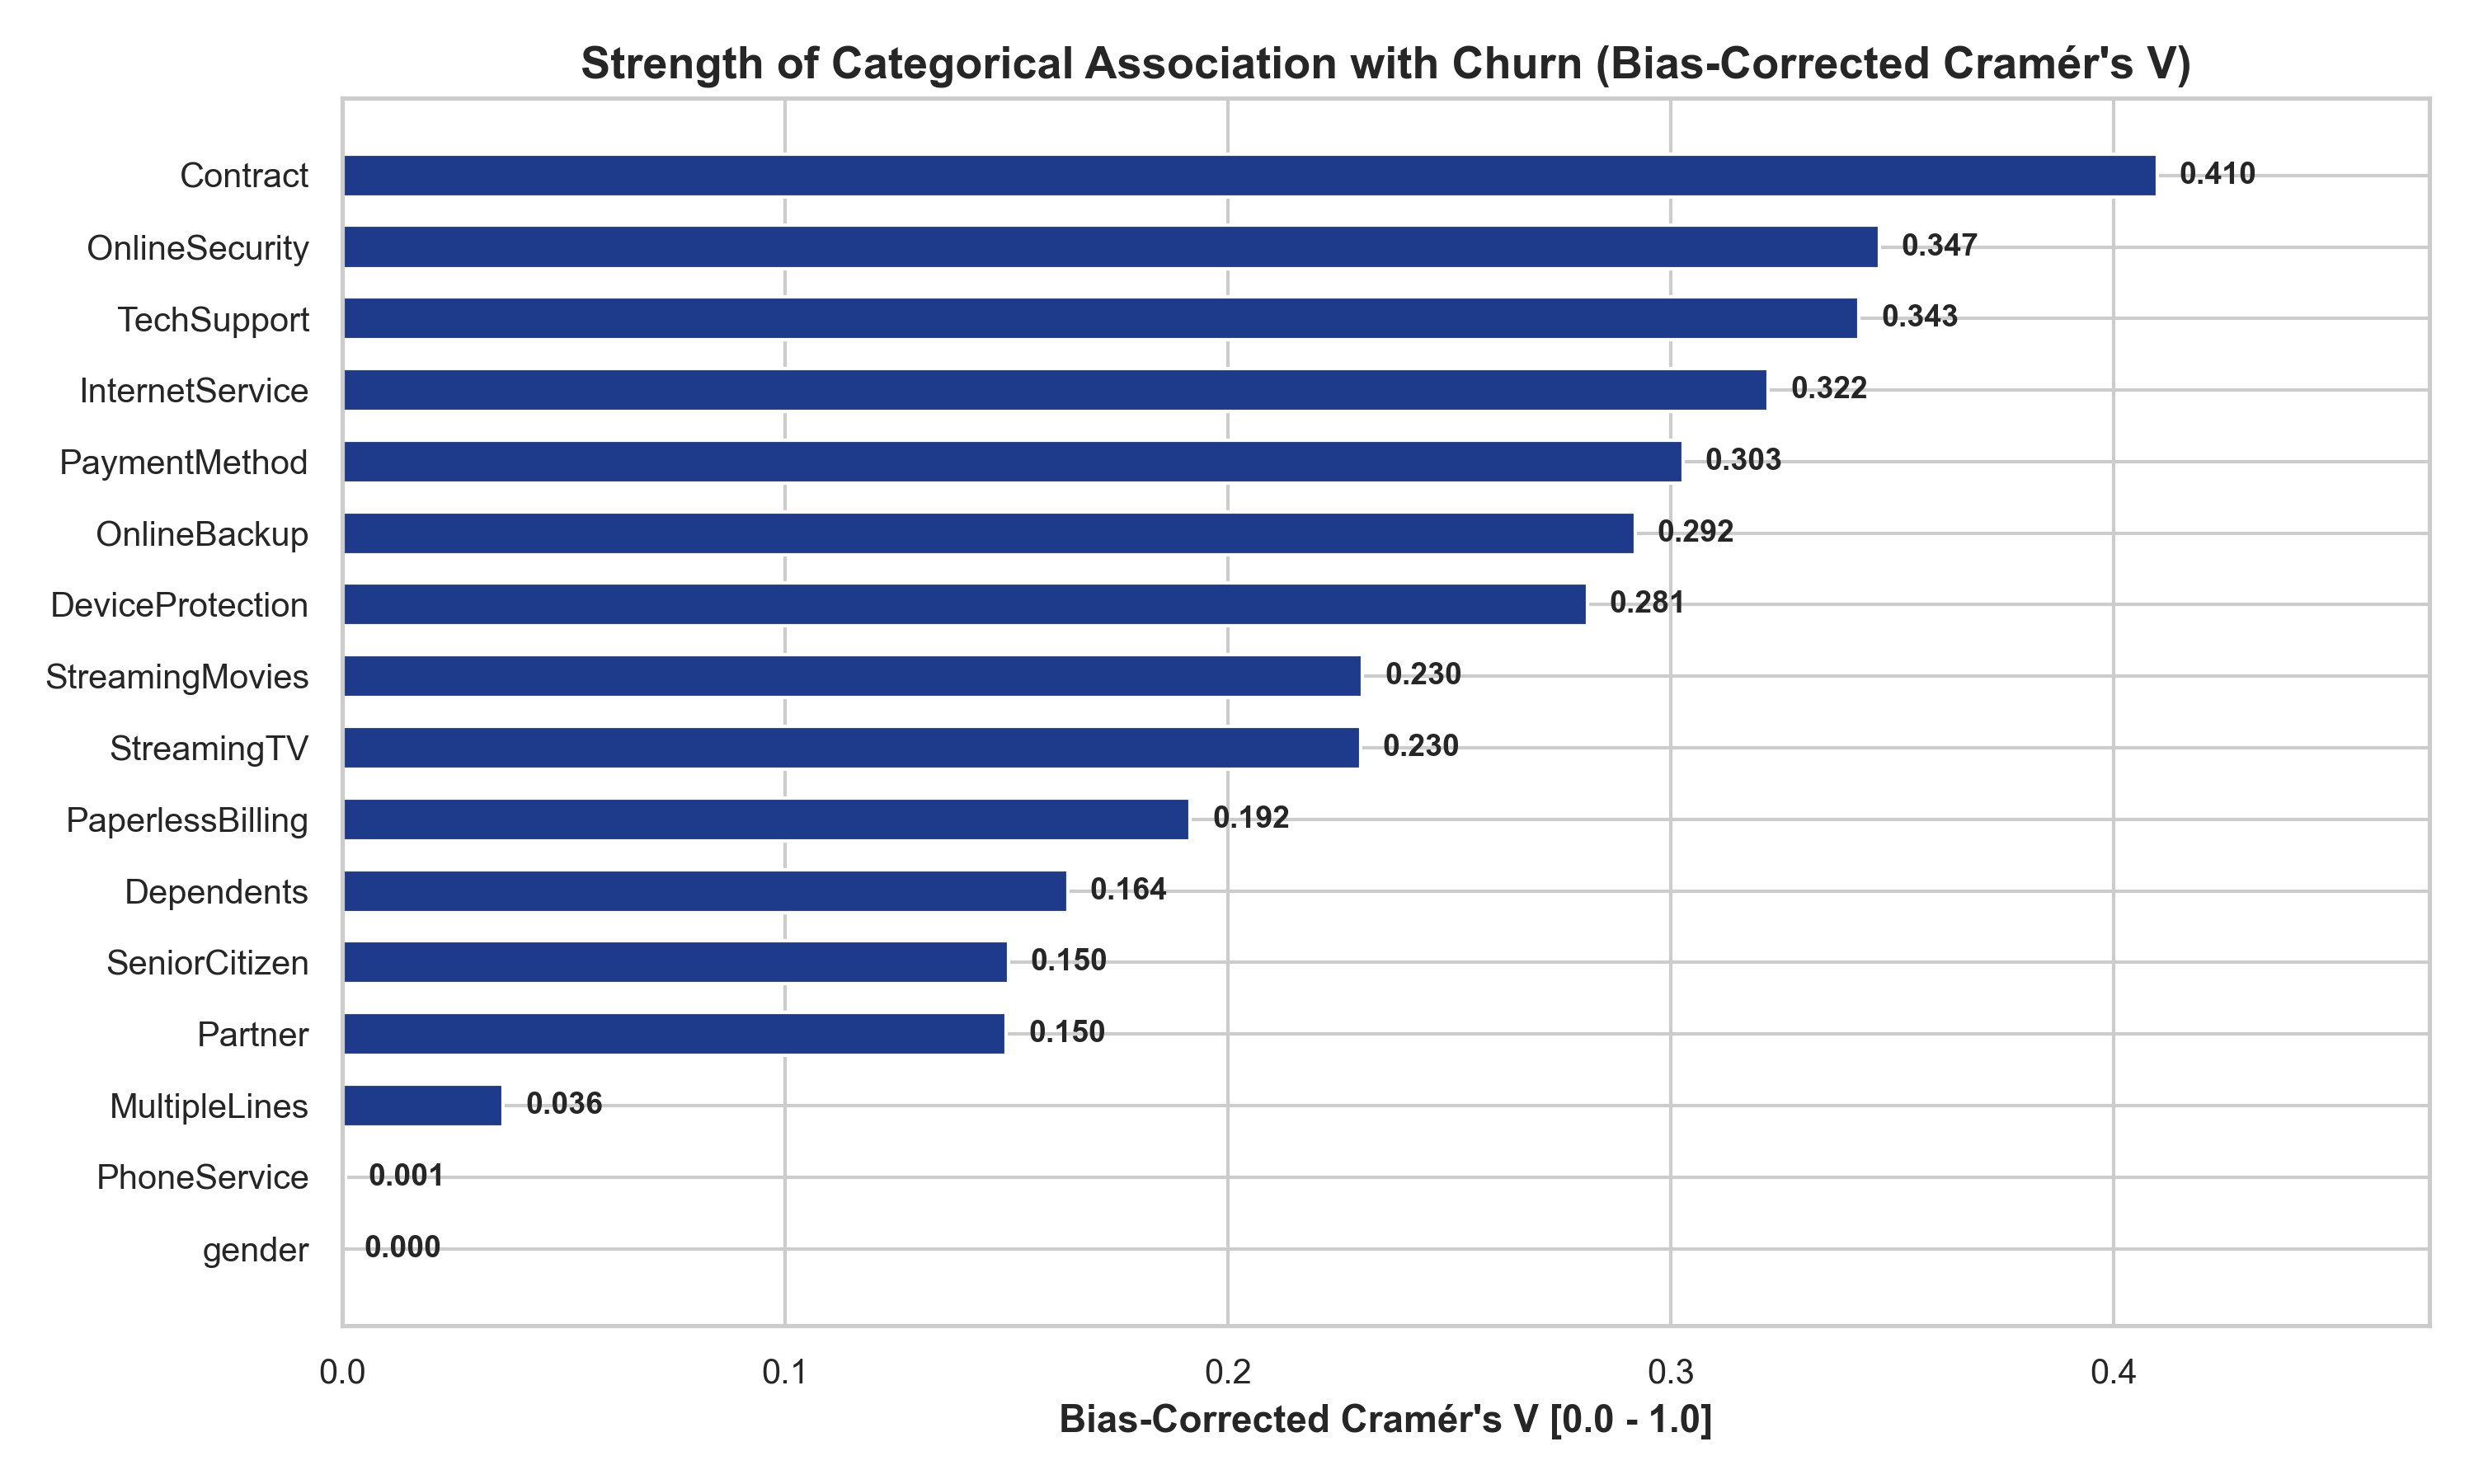

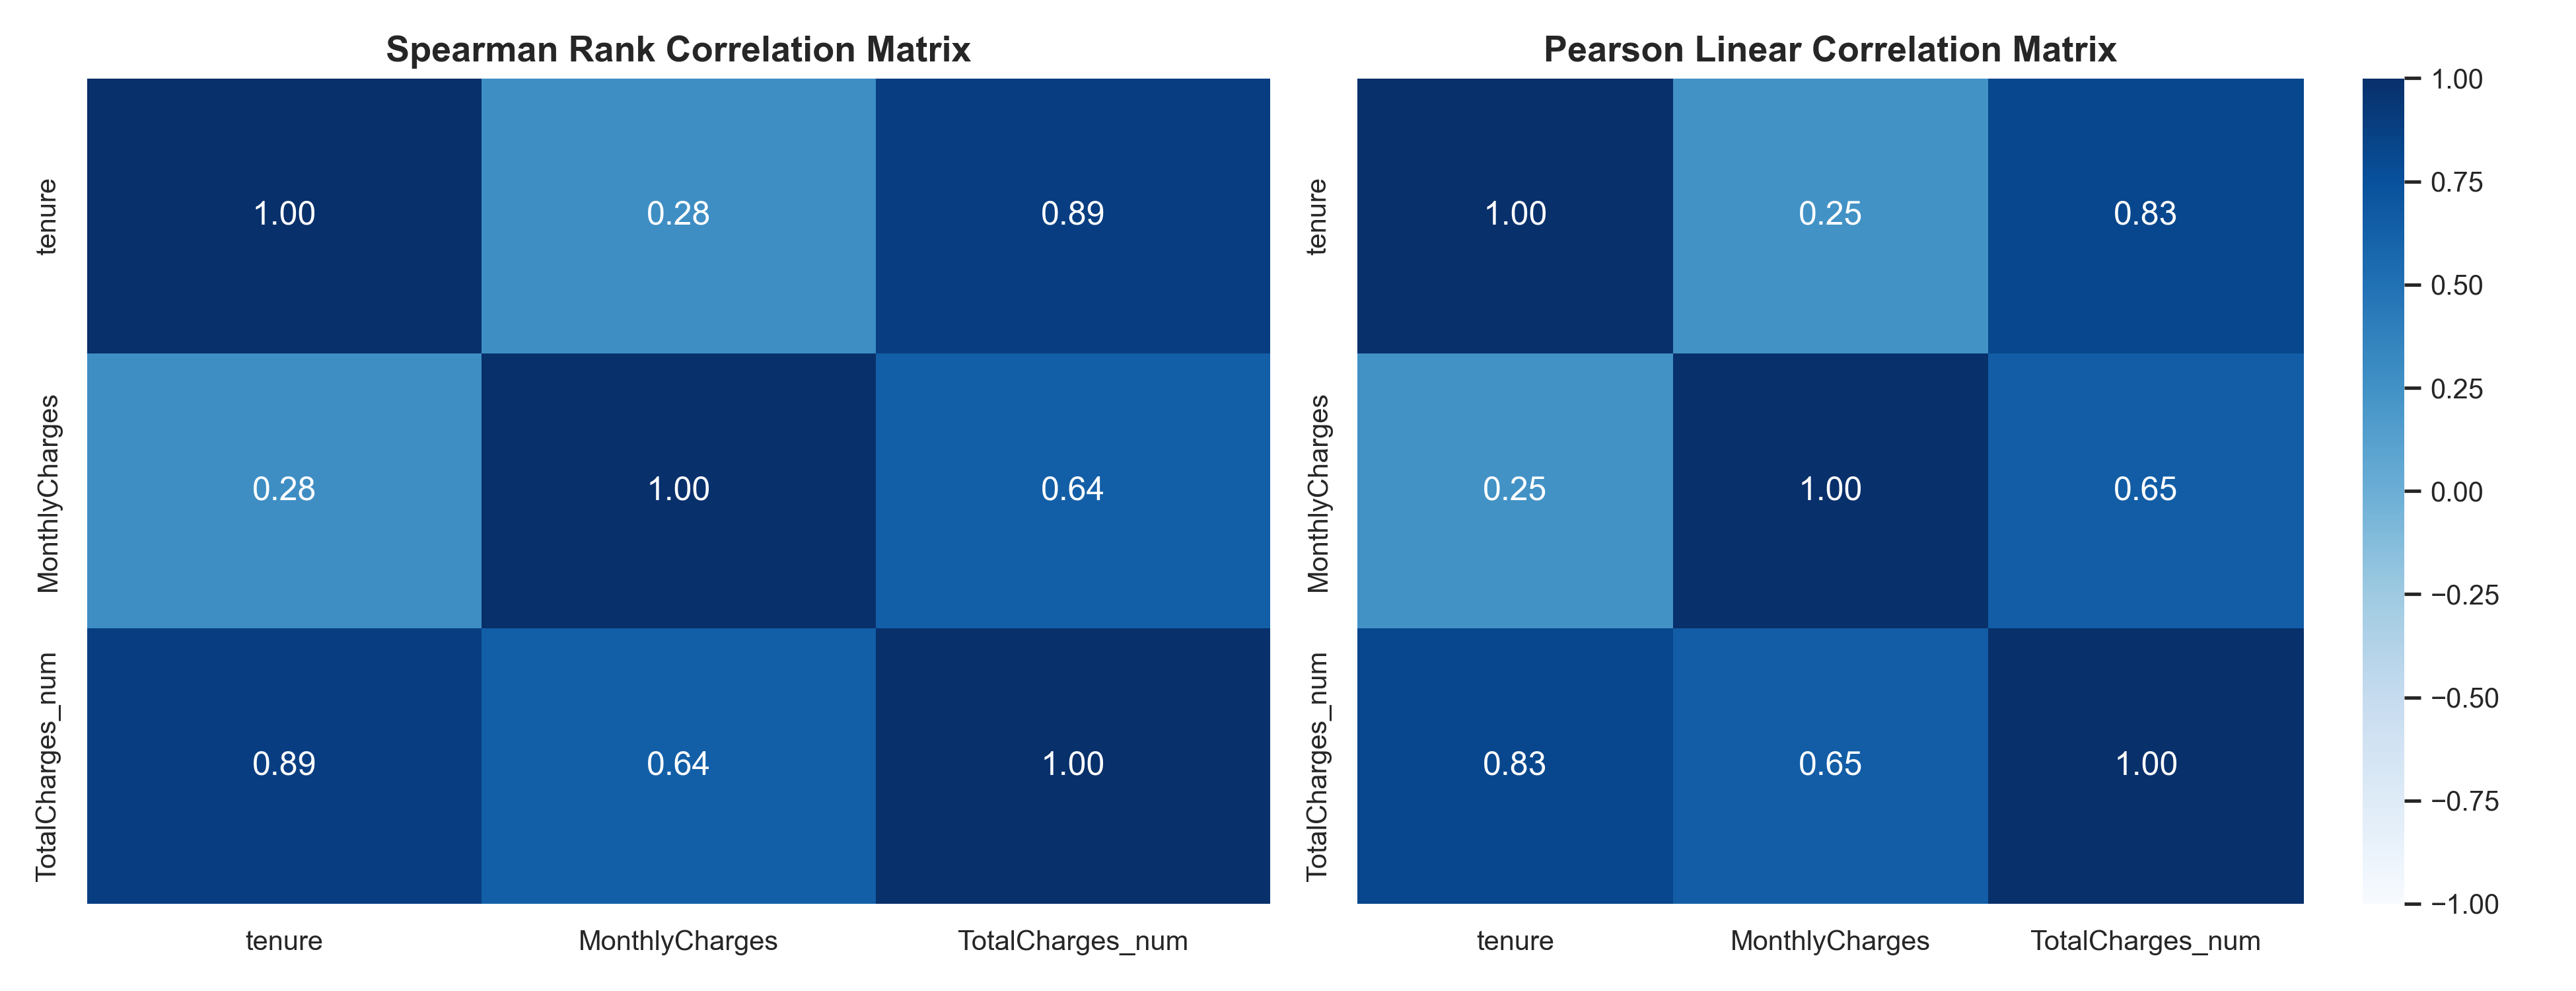

In [11]:
display(Image(filename=str(figures_dir / "16_categorical_associations_cramers_v.png")))
display(Image(filename=str(figures_dir / "15_numeric_correlation_matrix.png")))

### Q10: What data-quality or modelling concerns should be addressed before preprocessing?
1. **Identifier Exclusion**: `customerID` is 100% unique and must be excluded from modeling matrices.
2. **TotalCharges Preprocessing Pipeline**: The canonical raw CSV remains unmodified. In Phase 3, parse whitespace to NaN, validate missingness strictly against tenure == 0, and impute 0.0 before casting to float.
3. **Multicollinearity between Tenure and TotalCharges**: Spearman correlation of 0.889 indicates collinearity; tree models tolerate this, but regularized linear models will require attention.
4. **Ternary Categories**: Categories like `"No internet service"` and `"No phone service"` represent service structural states distinct from `"No"` and should not be collapsed blindly.
5. **Feature Directives**: Default One-Hot encoding for `Contract` (ordinal encoding evaluated only as an alternative experiment with documented spacing assumptions); engineer `OptionalServiceCount` across all 6 internet add-ons (scoring "No internet service" as 0); treat `ChargesRatio` as an experimental candidate requiring explicit zero-tenure branching.

## 3. Multivariate Interaction Analysis

We examine the interaction of `InternetService` with `TechSupport`, and `Contract` with `tenure_group`.

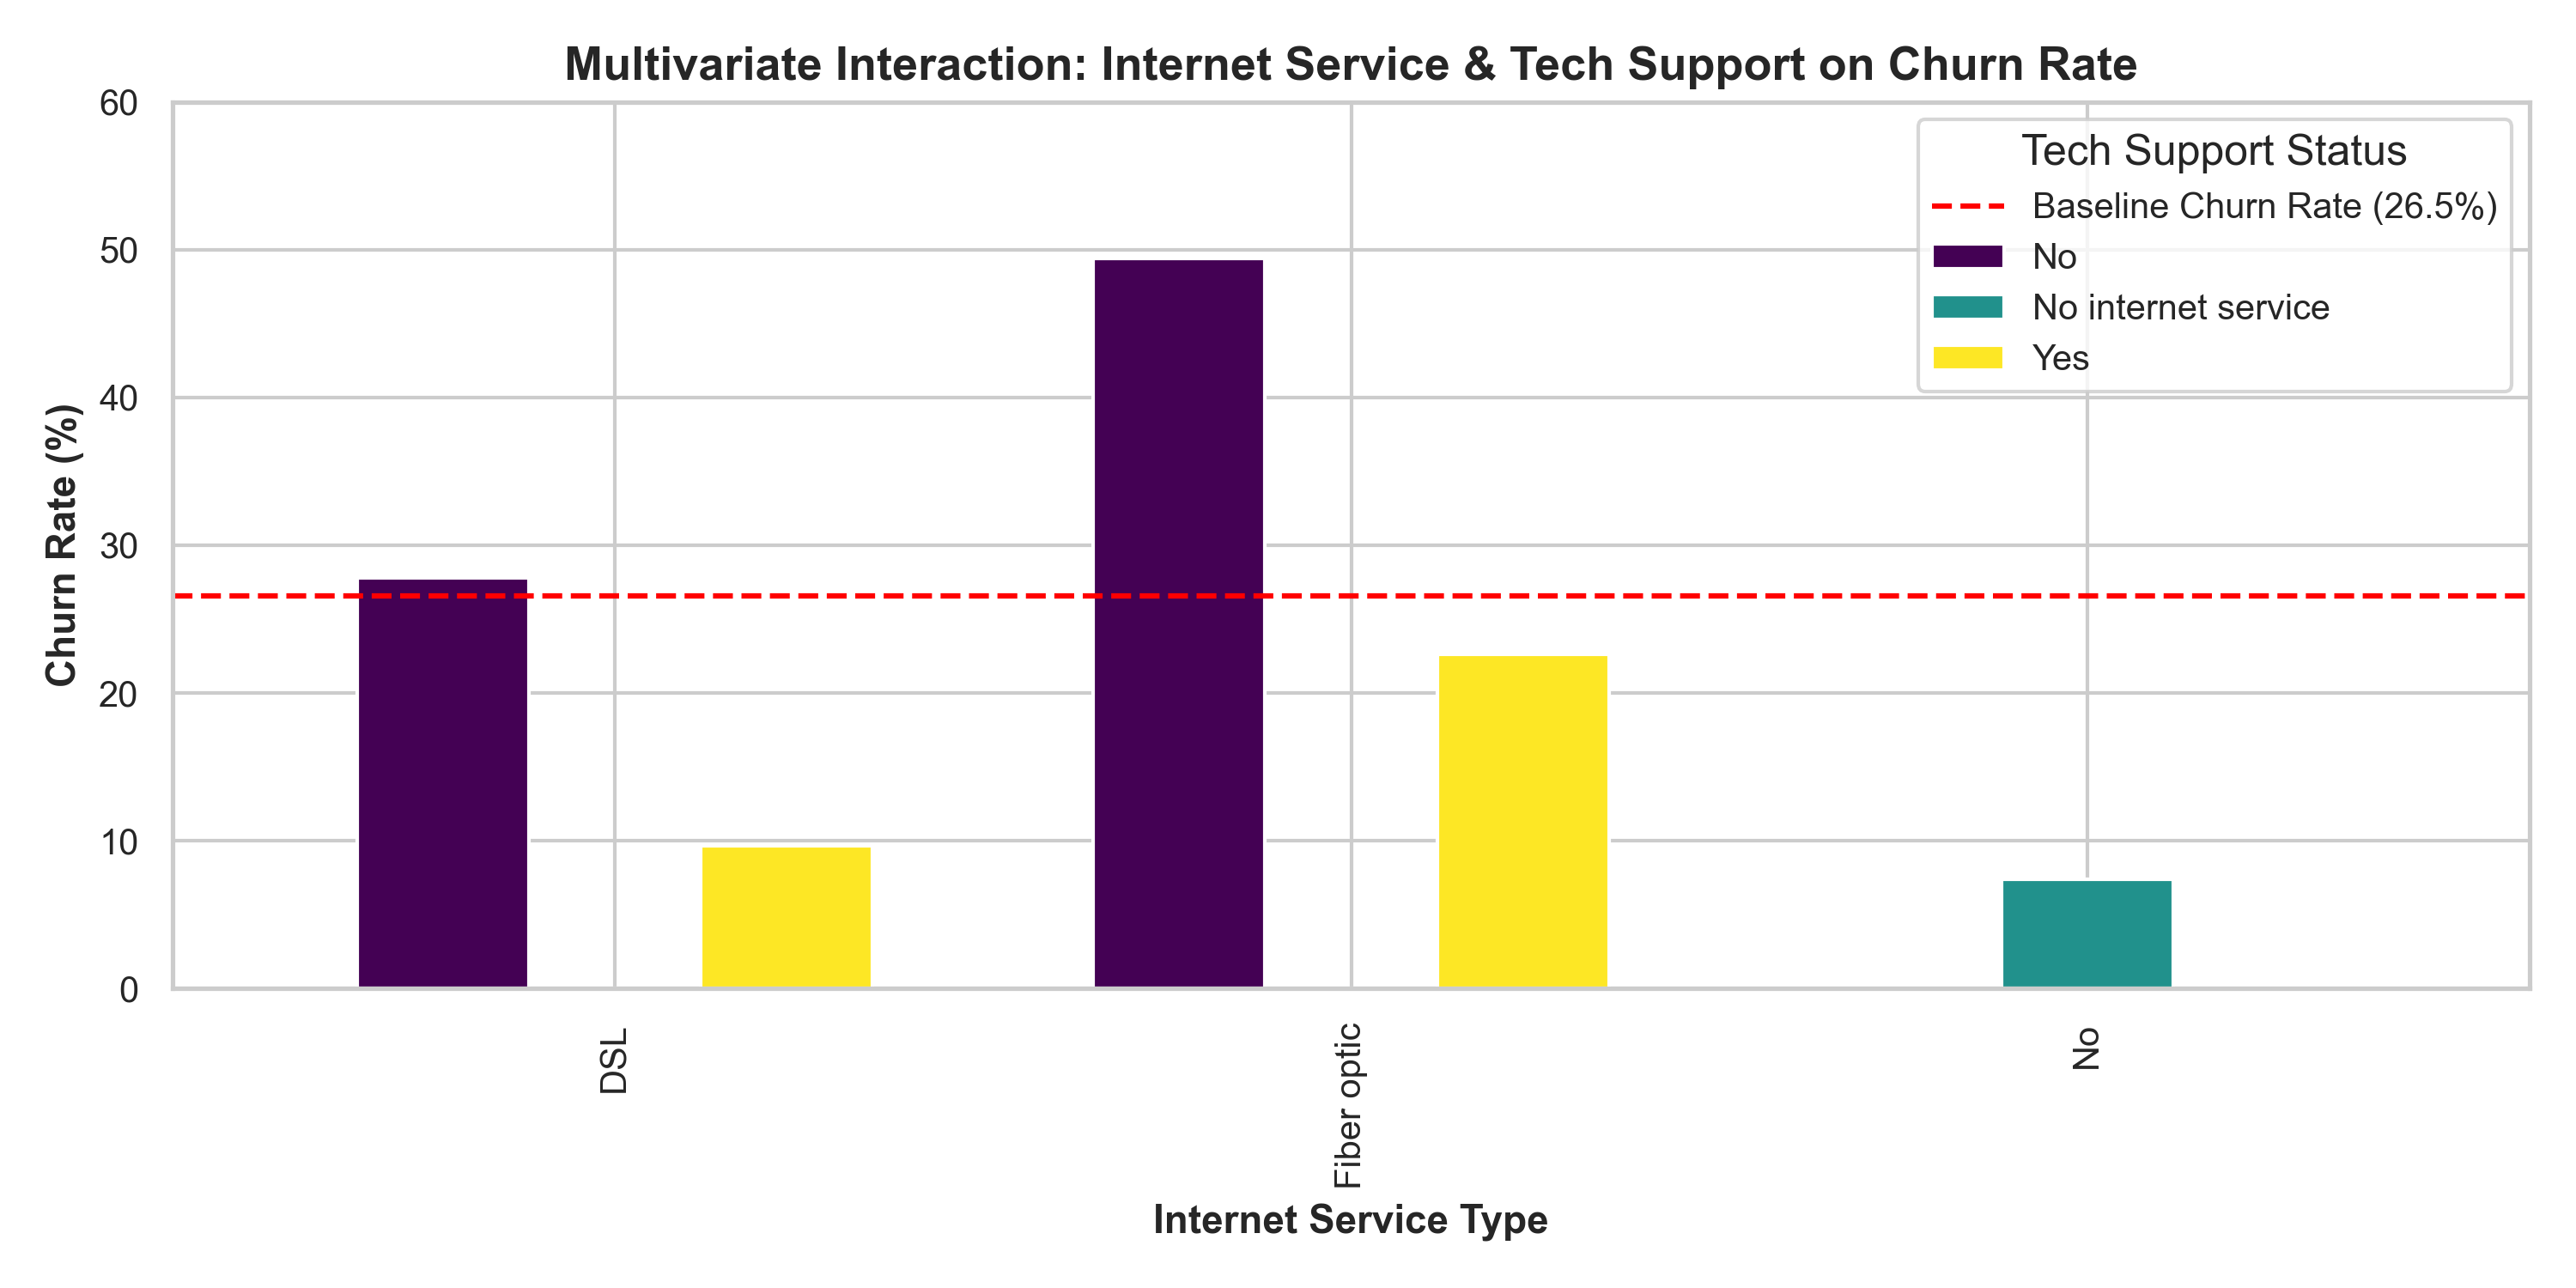

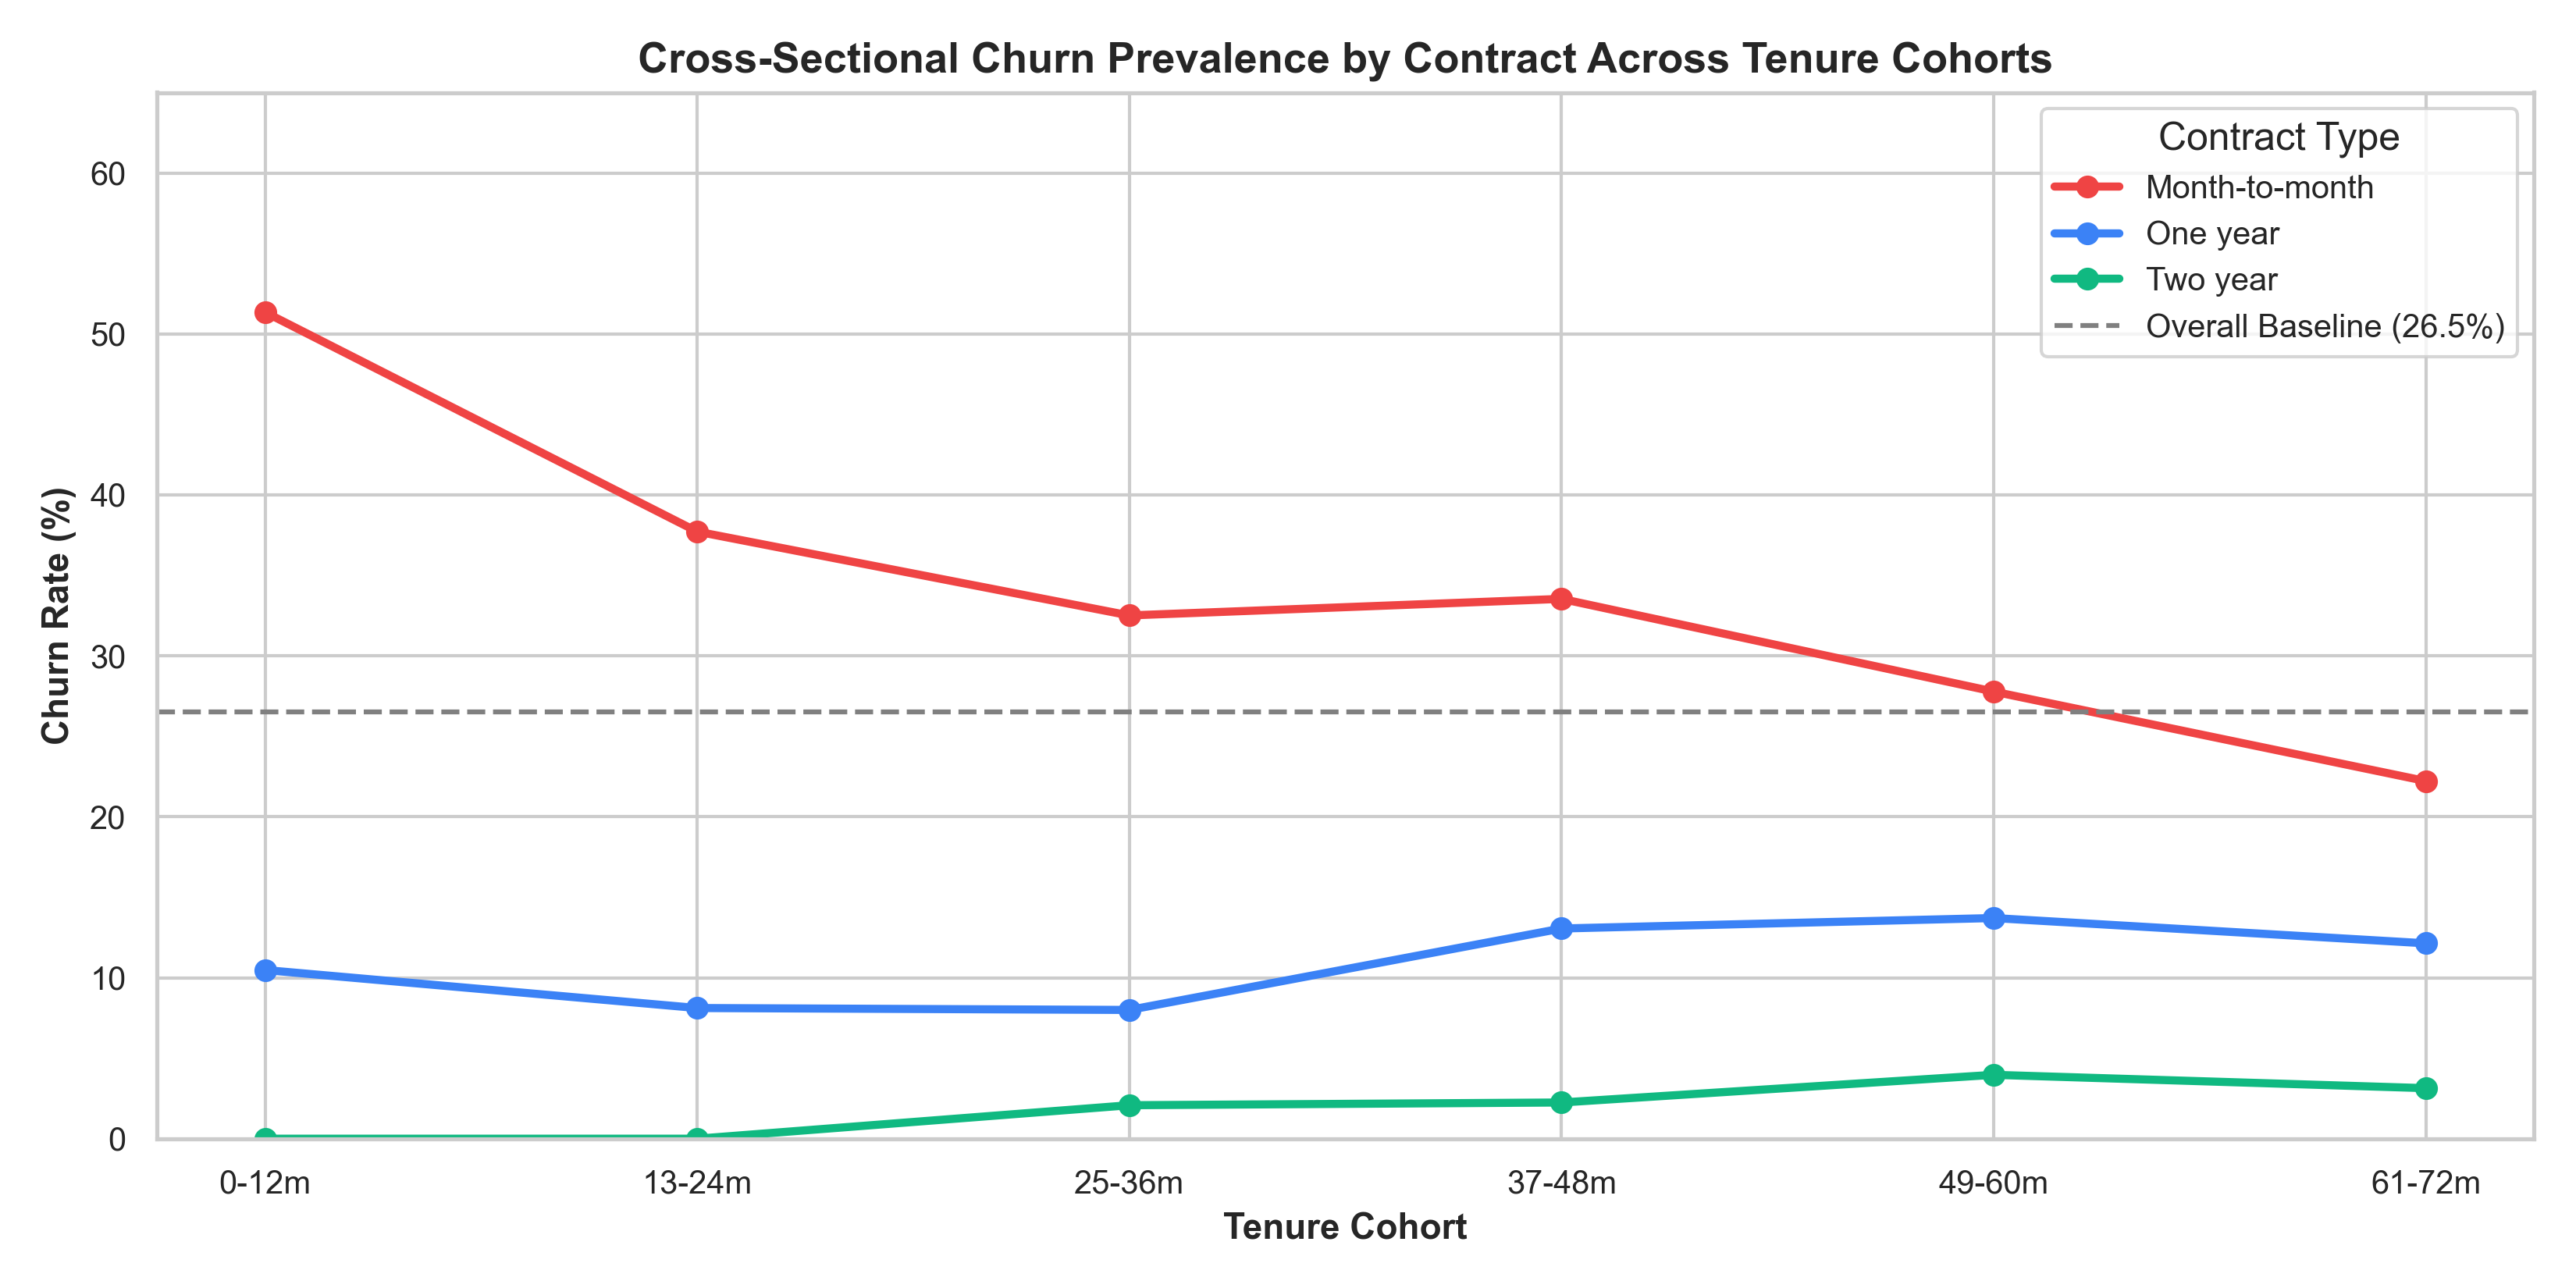

In [12]:
display(Image(filename=str(figures_dir / "12_multivariate_internet_and_support.png")))
display(Image(filename=str(figures_dir / "13_multivariate_contract_and_tenure.png")))

## 4. Formal Inferential Statistical Tests

We run Chi-Square tests of independence with Benjamini-Hochberg FDR correction on categorical features, and Mann-Whitney U / Welch's t-tests on numerical features.

In [13]:
cat_cols = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
]
cat_tests = compute_categorical_associations(df, cat_cols=cat_cols)
print("=== CATEGORICAL ASSOCIATIONS (CHI-SQUARE & CRAMER'S V WITH FDR ADJUSTMENT) ===")
print(cat_tests[['feature', 'chi2_statistic', 'cramers_v', 'fdr_p_value', 'significant']])

num_tests = compute_numerical_churn_tests(df, num_cols=["tenure", "MonthlyCharges", "TotalCharges"])
print("\n=== NUMERICAL TESTS (MANN-WHITNEY U & WELCH'S T WITH FDR ADJUSTMENT) ===")
print(num_tests[['feature', 'retained_median', 'churned_median', 'rank_biserial_r', 'mann_whitney_fdr_p', 'cohens_d']])

=== CATEGORICAL ASSOCIATIONS (CHI-SQUARE & CRAMER'S V WITH FDR ADJUSTMENT) ===
             feature  chi2_statistic  cramers_v    fdr_p_value  significant
0           Contract        1184.597     0.4098  9.380861e-257         True
1     OnlineSecurity         849.999     0.3470  2.128920e-184         True
2        TechSupport         828.197     0.3425  7.696448e-180         True
3    InternetService         732.310     0.3220  3.828715e-159         True
4      PaymentMethod         648.142     0.3027  1.178353e-139         True
5       OnlineBackup         601.813     0.2919  5.546025e-131         True
6   DeviceProtection         558.419     0.2811  1.258336e-121         True
7    StreamingMovies         375.661     0.2304   5.335514e-82         True
8        StreamingTV         374.204     0.2299   9.829324e-82         True
9   PaperlessBilling         258.278     0.1915   6.517367e-58         True
10        Dependents         189.129     0.1638   7.163522e-43         True
11     Se